# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

current_dir = os.path.dirname(os.path.abspath("Incremental-Learning-MycroftMinds"))
parent_dir = os.path.dirname(current_dir)
# Insert the parent directory at the beginning of sys.path if it's not already there.
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

## Import external libs and internal models

In [ ]:
import time
from typing import Optional, Tuple, Dict, Any, List

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
#from river.forest import ARFRegressor
#from river.ensemble import BaggingRegressor, SRPRegressor
#from river.drift.binary import DDM, EDDM
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.trees import fastodt
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_valid_splits_seq_fit_predict

# Download the splitted data

In [ ]:
# check you data dir and file prefixes
data_dir = '../data'

## Pick the hourly or 5-min granularity data
- WFV, train+=28 (train set increasing), validation=28, hourly granularity
- WFV, train+=28 (train set increasing), validation=28, 5-min granularity

In [4]:
HOURLY = True

In [5]:
# Measure loading time
start_time = time.time()

# Load data
if HOURLY:
    train, valid, test = load_dataset(data_dir=data_dir, prefix='8_dev_hour_wfv', use_numpy=True)
    features = ['time', 'device_id', 'export_energy_active', 'hour', 'weekday', 'month', 
                'total_power_active_lag_1h', 'total_power_active_lag_24h', 'total_power_active_lag_168h', 
                'total_power_reactive_lag_1h', 'total_power_reactive_lag_24h', 'total_power_reactive_lag_168h', 
                'total_power_apparent_lag_1h', 'total_power_apparent_lag_24h', 'total_power_apparent_lag_168h', 
                'import_energy_active_lag_1h', 'import_energy_active_lag_24h', 'import_energy_active_lag_168h', 
                'import_energy_reactive_lag_1h', 'import_energy_reactive_lag_24h', 'import_energy_reactive_lag_168h', 
                'export_energy_reactive_lag_1h', 'export_energy_reactive_lag_24h', 'export_energy_reactive_lag_168h', 
                'total_energy_active_lag_1h', 'total_energy_active_lag_24h', 'total_energy_active_lag_168h', 
                'total_energy_reactive_lag_1h', 'total_energy_reactive_lag_24h', 'total_energy_reactive_lag_168h']
else:
    train, valid, test = load_dataset(data_dir=data_dir, prefix='8_dev_5_min_wfv', use_numpy=True)
    # copy features from dataloader printouts
    features = ['time', 'device_id', 'hour', 'weekday', 'month',
                'total_power_active_lag_5m', 'total_power_active_lag_1h', 'total_power_active_lag_24h', 'total_power_active_lag_168h', 
                'total_power_reactive_lag_5m', 'total_power_reactive_lag_1h', 'total_power_reactive_lag_24h', 'total_power_reactive_lag_168h', 
                'total_power_apparent_lag_5m', 'total_power_apparent_lag_1h', 'total_power_apparent_lag_24h', 'total_power_apparent_lag_168h', 
                'import_energy_active_lag_5m', 'import_energy_active_lag_1h', 'import_energy_active_lag_24h', 'import_energy_active_lag_168h', 
                'export_energy_active_lag_5m', 'export_energy_active_lag_1h', 'export_energy_active_lag_24h', 'export_energy_active_lag_168h', 
                'import_energy_reactive_lag_5m', 'import_energy_reactive_lag_1h', 'import_energy_reactive_lag_24h', 'import_energy_reactive_lag_168h', 
                'export_energy_reactive_lag_5m', 'export_energy_reactive_lag_1h', 'export_energy_reactive_lag_24h', 'export_energy_reactive_lag_168h', 
                'total_energy_active_lag_5m', 'total_energy_active_lag_1h', 'total_energy_active_lag_24h', 'total_energy_active_lag_168h', 
                'total_energy_reactive_lag_5m', 'total_energy_reactive_lag_1h', 'total_energy_reactive_lag_24h', 'total_energy_reactive_lag_168h']

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 10 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 10 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.04 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 10 splits
Validation data: 10 splits
First train split shape: X=(5085, 30), y=(5085,)
First valid split shape: X=(5273, 30), y=(5273,)

Memory usage:
Train: 68.14 MB
Valid: 11.54 MB
Test: 3.28 MB
Total: 82.96 MB


# Model evaluation

## 5-minutes granularity

### Baseline model (predict previous value)

In [9]:
device_period_metrics = {}
for split in valid:
    for device_id in set(split[0][:, 1]):  # Assuming device_id is in the second column
        X_valid, y_valid = get_device_data(split, device_id=device_id)
        y_pred = y_valid.shift(1)
        y_pred.iloc[0] = y_valid.iloc[0]
        
        device_metrics = calculate_metrics(
            y_valid,
            y_pred,
            device_id,
            f"{X_valid[0, 0]} - {X_valid[-1, 0]}", 
            verbose=True
            )
        
        if device_id not in device_period_metrics:
            device_period_metrics[device_id] = []
        device_period_metrics[device_id].append(device_metrics)

all_time_metrics = all_time_aggregation_metrics(device_period_metrics, verbose=True)


Metrics for Device: 3617dc75-38d4-4875-b66c-64f896b5c9f1 | Period: 2024-02-03 09:00:11.352000 - 2024-03-01 20:45:11.995000
5-Minute Metrics:
--------------------------------------------------
	RMSE: 444.8837
	MAE: 70.0085
	MAPE: 41.7494%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 324.8706
	MAE: 65.2532
	MAPE: 4.1428%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 7.7871
	MAE: 4.7458
	MAPE: 0.0147%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 17.8797
	MAE: 14.0990
	MAPE: 0.0074%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 26.1007
	MAE: 26.1007
	MAPE: 0.0029%
Metrics for Device: a4b80cd7-5438-44cd-8257-c9ac81684822 | Period: 2024-02-03 09:00:03.444000 - 2024-03-01 20:50:04

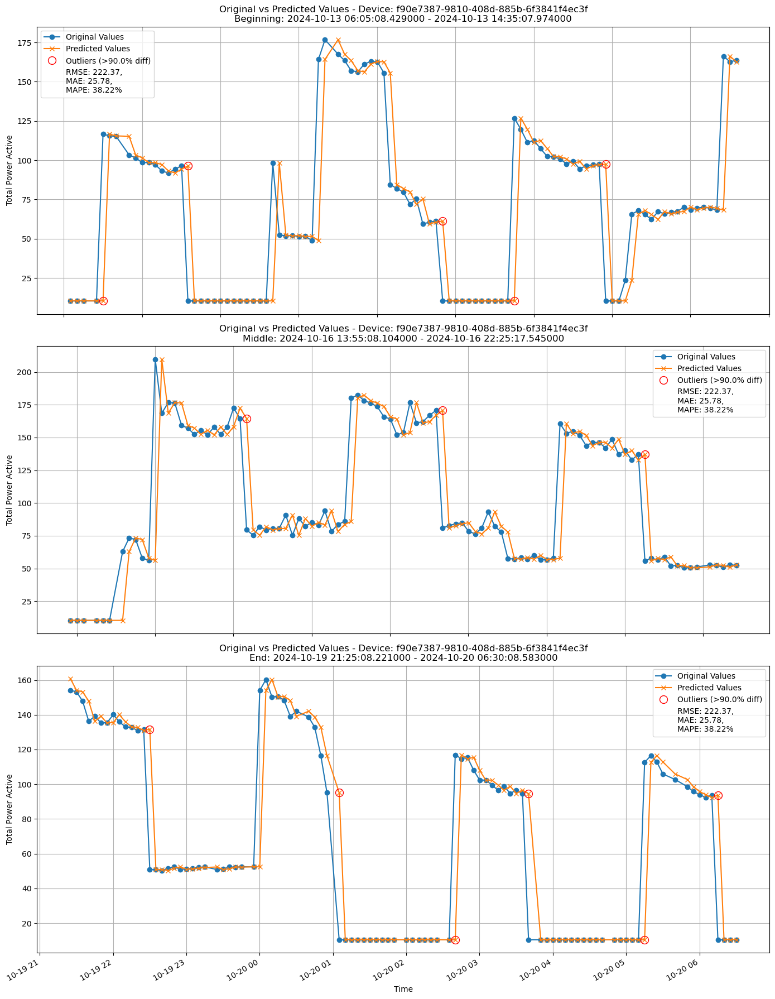

In [ ]:
plot_part_predictions(X_valid, y_valid, y_pred, data_show=100, device_id=device_id)

#### Hourly aggregated predictions with outliers

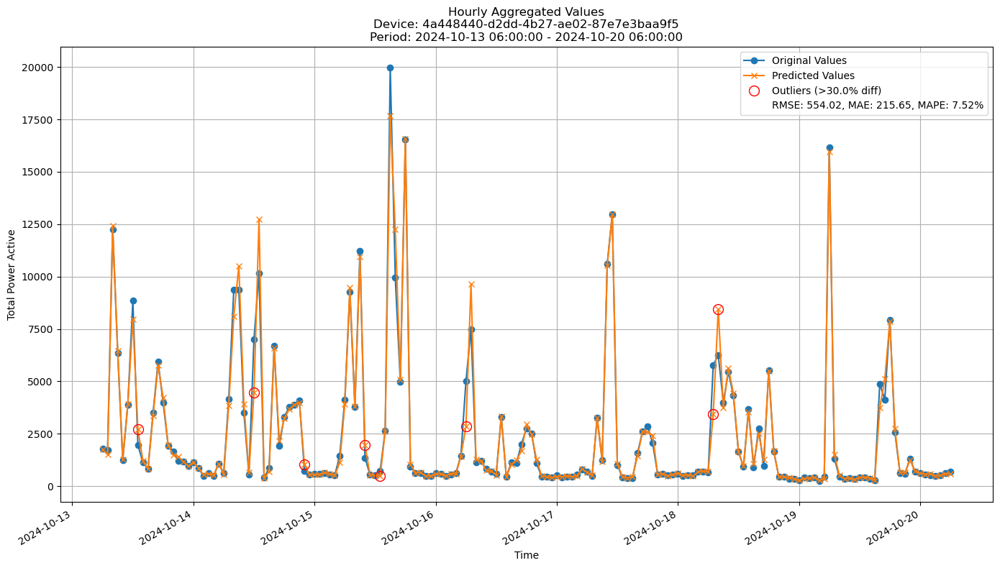

In [ ]:
plot_hourly_predictions(X_valid, 
                              y_valid, 
                              y_pred, 
                              device_id=device_id, 
                              outlier_threshold=0.3)

### GBDT

In [ ]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor(
    n_estimators=150,
    learning_rate=0.05,
    subsample=0.8,
    max_depth=5,
    random_state=42)

gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model=gbdt,
    train=train,
    valid=valid,
    incremental=False,
    update_freq=update_freq,
    start_split=2,
    end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 2:   0%|          | 0/8 [00:00<?, ?it/s]


Retraining model on data from 2024-01-07 23:00:04.091000 to 2024-03-29 10:45:03.563000

Time: 92.19 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2024-03-29 10:50:03.949000 to 2024-04-12 10:50:03.947000

-------------------------

Retraining model on data from 2024-01-07 23:00:04.091000 to 2024-04-12 10:50:03.947000

Time: 110.47 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2024-04-12 10:55:03.998000 to 2024-04-25 19:20:04.081000

-------------------------
Metrics for Device: a4b80cd7-5438-44cd-8257-c9ac81684822 | Period: 2024-03-29 10:50:03.949000 - 2024-04-25 19:20:04.081000
5-Minute Metrics:
--------------------------------------------------
	RMSE: 117.7647
	MAE: 76.7860
	MAPE: 20.6211%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 1145.0467
	MAE: 757.5102
	MAPE: 18.1678%
-------------------------------------------

Processing devices in split 3:   0%|          | 0/8 [00:00<?, ?it/s]


Retraining model on data from 2024-01-07 23:00:04.091000 to 2024-04-25 19:20:04.081000

Time: 125.68 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2024-04-25 19:25:03.174000 to 2024-05-09 19:20:03.757000

-------------------------

Retraining model on data from 2024-01-07 23:00:04.091000 to 2024-05-09 19:20:03.757000

Time: 142.86 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2024-05-09 19:25:04.017000 to 2024-05-22 23:00:03.847000

-------------------------
Metrics for Device: a4b80cd7-5438-44cd-8257-c9ac81684822 | Period: 2024-04-25 19:25:03.174000 - 2024-05-22 23:00:03.847000
5-Minute Metrics:
--------------------------------------------------
	RMSE: 126.0344
	MAE: 81.5257
	MAPE: 30.5334%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 1143.7573
	MAE: 735.0416
	MAPE: 25.2738%
------------------------------------------

In [ ]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_predictions, verbose=True)
print("\n\Valid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_predictions, verbose=True)

#### Feature importance
[WiP] Right now only for the last split and last device

In [54]:
feat_imps = sorted(
    zip(features[2:], gbdt.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


[('total_power_apparent_lag_5m', 0.18417988126089468),
 ('total_power_active_lag_5m', 0.15010298077472534),
 ('total_power_reactive_lag_5m', 0.052583067145842655),
 ('total_power_reactive_lag_1h', 0.04732318338432402),
 ('total_power_reactive_lag_24h', 0.03611312196247886),
 ('total_power_active_lag_1h', 0.03579456275633742),
 ('total_power_apparent_lag_1h', 0.0336277057104996),
 ('total_power_reactive_lag_168h', 0.0325056901339694),
 ('total_power_apparent_lag_168h', 0.0277691436038376),
 ('total_power_apparent_lag_24h', 0.027509914934285753),
 ('total_power_active_lag_168h', 0.026437900300439535),
 ('total_power_active_lag_24h', 0.024679449710935712),
 ('hour', 0.020217624088099576),
 ('export_energy_reactive_lag_1h', 0.018905641224992102),
 ('total_energy_reactive_lag_5m', 0.01817268936066407),
 ('import_energy_active_lag_5m', 0.015973184881873475),
 ('import_energy_active_lag_168h', 0.015544524864966882),
 ('total_energy_active_lag_5m', 0.015262617283512548),
 ('total_energy_reacti

#### Training plots
Plot only the last period of predictions

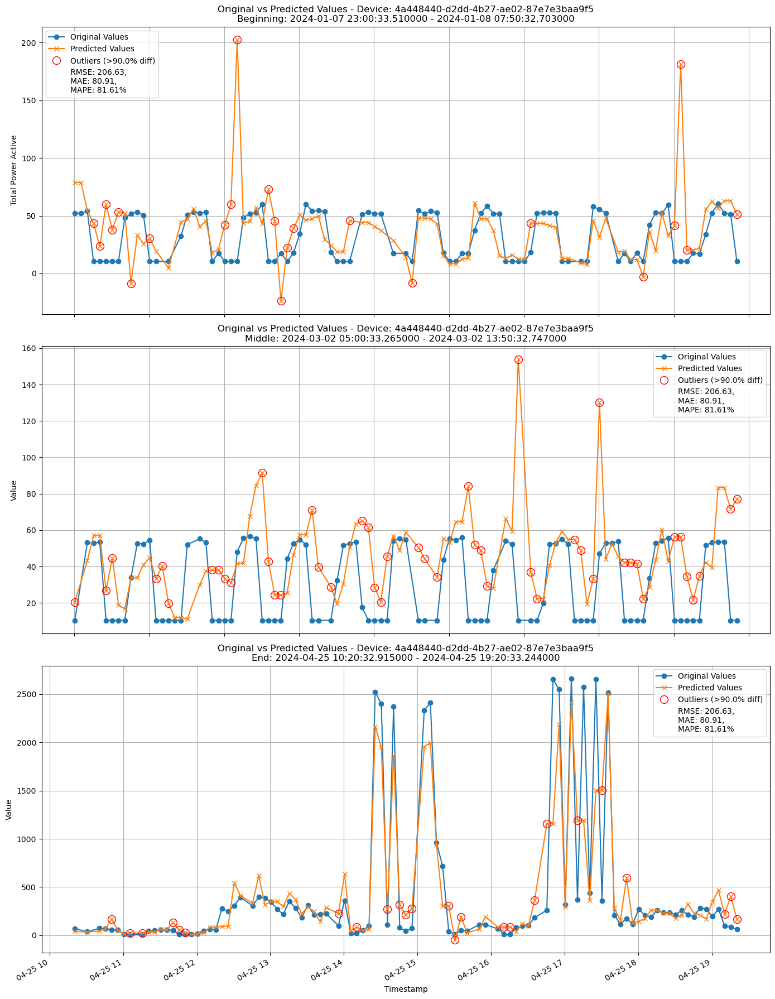

In [ ]:
for device_id in gbdt_train_period_predictions.keys():
    print(f"\n\nDevice ID: {device_id}")
    print("-"*10)
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    plot_part_predictions(y_train, y_pred_train, data_show=100, device_id=device_id)
    print("="*25)

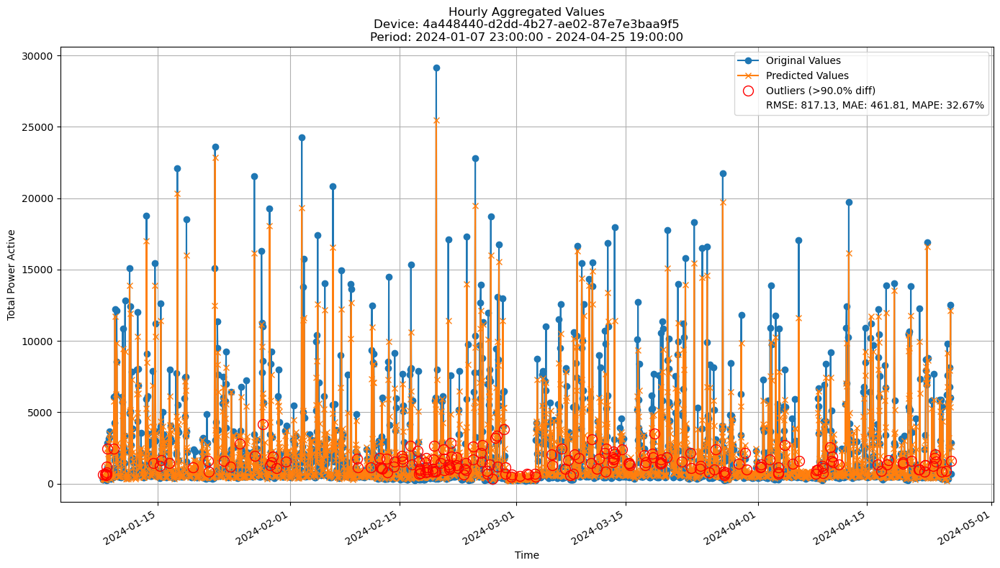

In [ ]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=0.9)

#### Validation plots
Plot only the last period of predictions

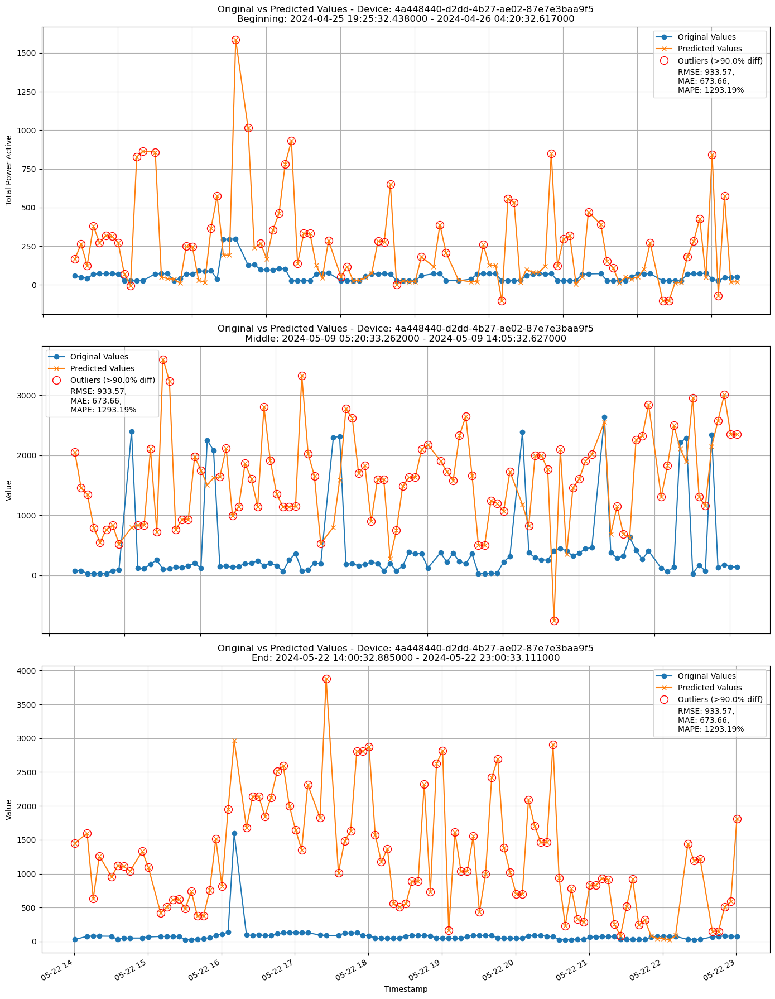

In [ ]:
for device_id in gbdt_valid_period_predictions.keys():
    print(f"\n\nDevice ID: {device_id}")
    print("-"*10)
    y_valid = gbdt_valid_period_predictions[device_id][-1]['y_true']
    y_pred_valid = gbdt_valid_period_predictions[device_id][-1]['y_pred']
    plot_part_predictions(y_valid, y_pred_valid, data_show=100, device_id=device_id)
    print("="*25)

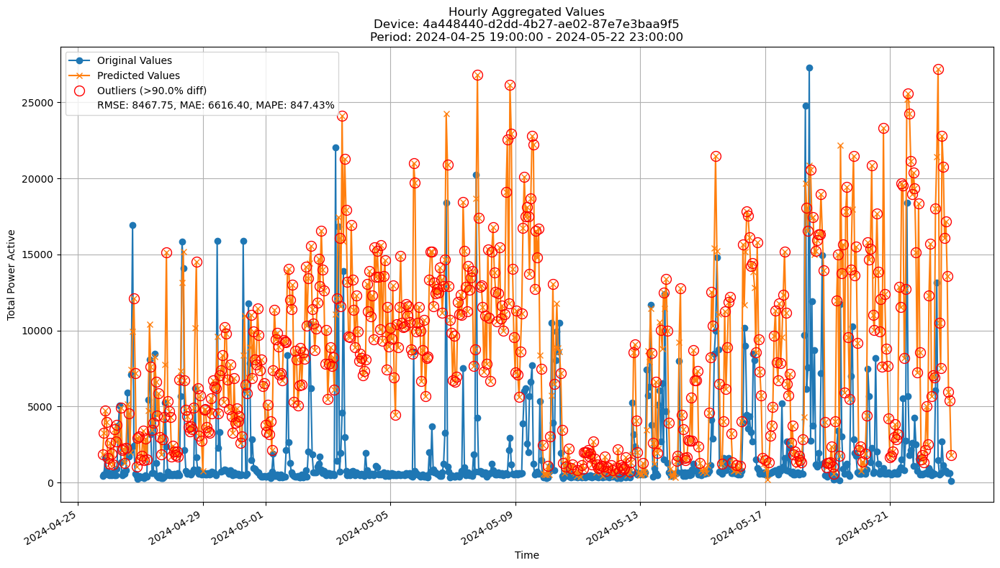

In [ ]:
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = gbdt_valid_period_predictions[device_id][-1]['y_true']
    y_pred_valid = gbdt_valid_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=0.9)

### Random Forest model

In [ ]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor(
    n_estimators=150, 
    max_depth=5, 
    random_state=42, 
    n_jobs=-1)

rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model=rf, 
    train=train, 
    valid=valid, 
    incremental=False, 
    update_freq=update_freq, 
    start_split=2, 
    end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 2:   0%|          | 0/8 [00:00<?, ?it/s]


Retraining model on data from 2024-01-07 23:00:04.091000 to 2024-03-29 10:45:03.563000

Time: 16.04 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2024-03-29 10:50:03.949000 to 2024-04-12 10:50:03.947000

-------------------------

Retraining model on data from 2024-01-07 23:00:04.091000 to 2024-04-12 10:50:03.947000

Time: 19.04 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2024-04-12 10:55:03.998000 to 2024-04-25 19:20:04.081000

-------------------------
Metrics for Device: a4b80cd7-5438-44cd-8257-c9ac81684822 | Period: 2024-03-29 10:50:03.949000 - 2024-04-25 19:20:04.081000
5-Minute Metrics:
--------------------------------------------------
	RMSE: 100.1487
	MAE: 61.2518
	MAPE: 18.1168%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 990.8613
	MAE: 612.1586
	MAPE: 16.0596%
---------------------------------------------

Processing devices in split 3:   0%|          | 0/8 [00:00<?, ?it/s]


Retraining model on data from 2024-01-07 23:00:04.091000 to 2024-04-25 19:20:04.081000

Time: 23.57 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2024-04-25 19:25:03.174000 to 2024-05-09 19:20:03.757000

-------------------------

Retraining model on data from 2024-01-07 23:00:04.091000 to 2024-05-09 19:20:03.757000

Time: 27.07 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2024-05-09 19:25:04.017000 to 2024-05-22 23:00:03.847000

-------------------------
Metrics for Device: a4b80cd7-5438-44cd-8257-c9ac81684822 | Period: 2024-04-25 19:25:03.174000 - 2024-05-22 23:00:03.847000
5-Minute Metrics:
--------------------------------------------------
	RMSE: 88.2728
	MAE: 58.6667
	MAPE: 21.8647%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 815.9628
	MAE: 561.6364
	MAPE: 18.5882%
----------------------------------------------

In [ ]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, verbose=True)
print("\n\Valid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, verbose=True)

#### Training plots
Plot only the last period of predictions

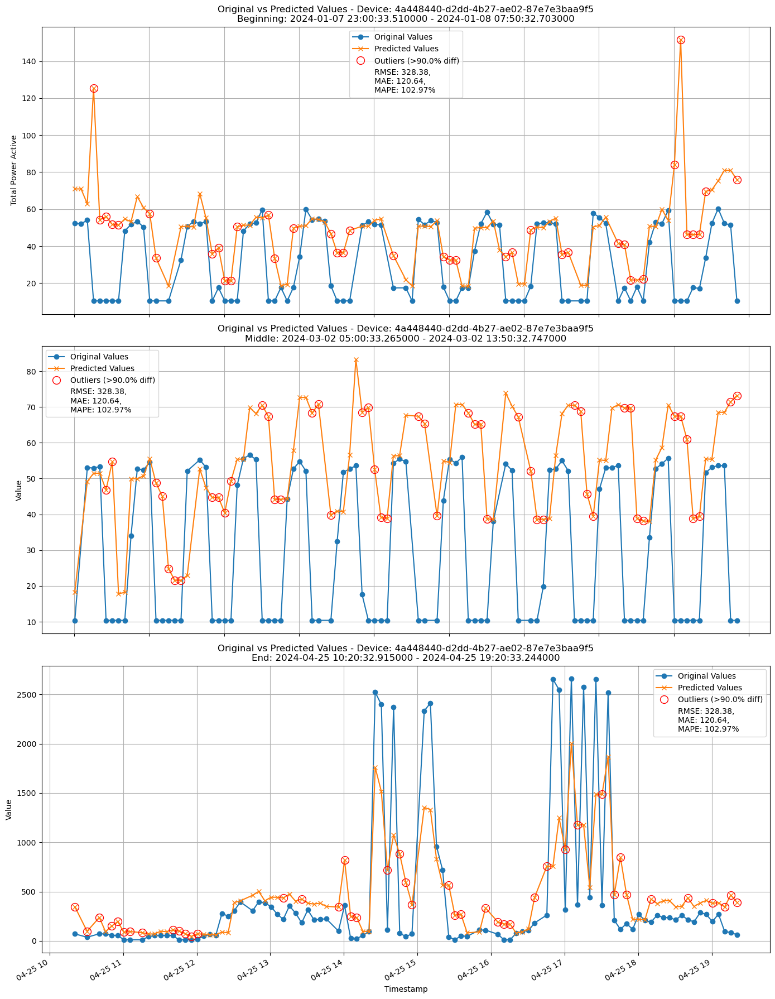

In [ ]:
for device_id in rf_train_period_predictions.keys():
    print(f"\n\nDevice ID: {device_id}")
    print("-"*10)
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_part_predictions(y_train, y_pred_train, data_show=100, device_id=device_id)
    print("="*25)


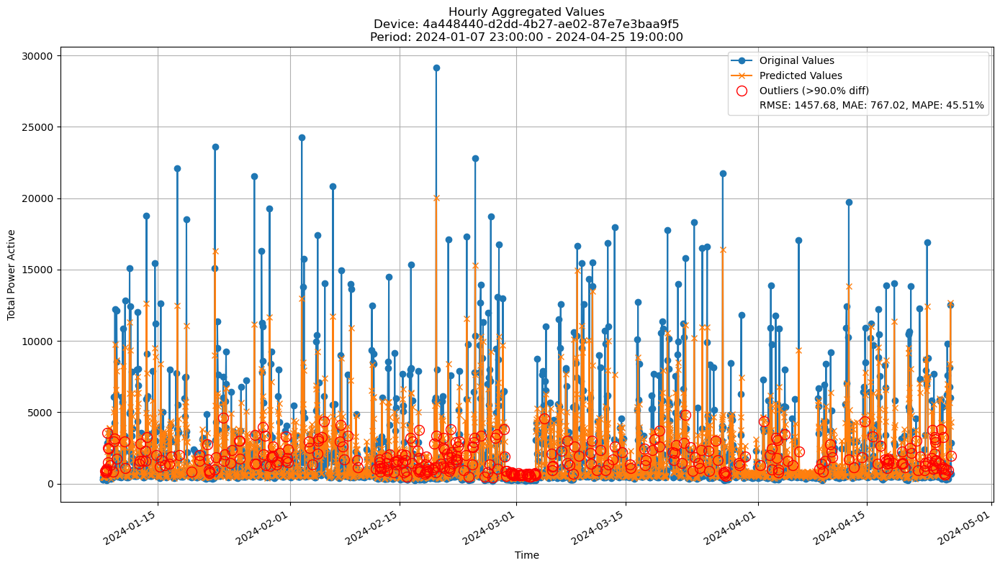

In [ ]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=0.9)

#### Validation plots
Plot only the last period of predictions

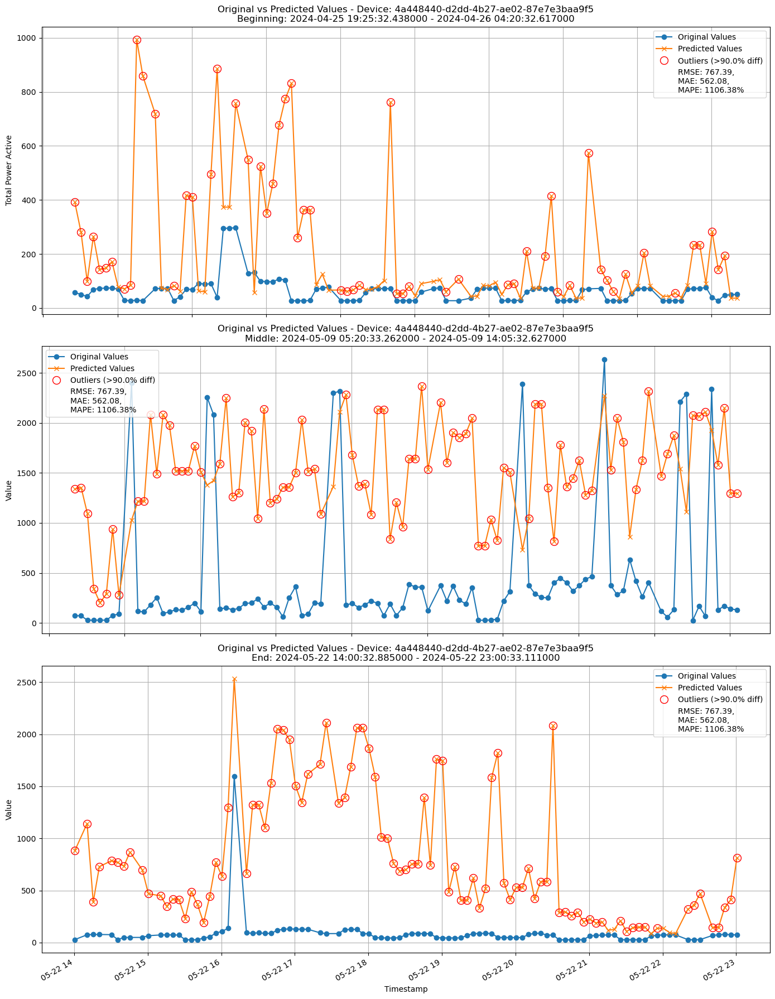

In [ ]:
for device_id in rf_valid_period_predictions.keys():
    print(f"\n\nDevice ID: {device_id}")
    print("-"*10)
    y_valid = rf_valid_period_predictions[device_id][-1]['y_true']
    y_pred_valid = rf_valid_period_predictions[device_id][-1]['y_pred']
    plot_part_predictions(y_valid, y_pred_valid, data_show=100, device_id=device_id)
    print("="*25)

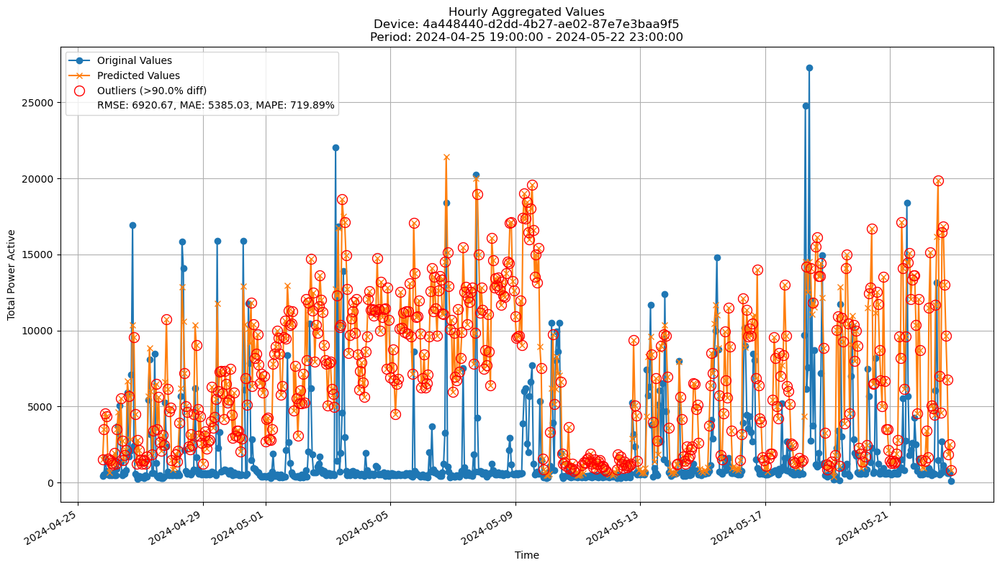

In [ ]:
for device_id in rf_valid_period_predictions.keys():
    y_valid = rf_valid_period_predictions[device_id][-1]['y_true']
    y_pred_valid = rf_valid_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=0.9)

### FastODT

In [ ]:
update_freq = "5m"  # for incremental models put the same as the data frequency to recreate real world scenario
grace_period = 10
split_confidence = 0.05
fodt = fastodt.FastODT(
        depth=20,
        grace_period=grace_period,
        split_confidence=split_confidence,
        option='hf'
    )

fodt_train_period_predictions, fodt_valid_period_predictions, \
fodt_train_period_metrics, fodt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model=fodt, 
    train=train, 
    valid=valid, 
    incremental=True, 
    update_freq=update_freq, 
    start_split=2, 
    end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 2:   0%|          | 0/8 [00:00<?, ?it/s]

Initial training on data from 2024-01-07 23:00:51.612000 to 2024-03-29 10:40:50.850000
Train predictions completed.
Metrics for Device: dd40019b-5b35-4fba-b0dd-16083c1fdb84 | Period: 2024-03-29 10:45:51.165000 - 2024-04-25 19:20:51.376000
5-Minute Metrics:
--------------------------------------------------
	RMSE: 90.5979
	MAE: 16.7040
	MAPE: 89.0005%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 469.9693
	MAE: 128.9082
	MAPE: 31.9609%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 3026.0147
	MAE: 2360.0980
	MAPE: 27.3244%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 13200.1831
	MAE: 12471.3126
	MAPE: 26.9202%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 25312.4646
	MAE: 2531

Processing devices in split 3:   0%|          | 0/8 [00:00<?, ?it/s]

Initial training on data from 2024-01-07 23:00:51.612000 to 2024-04-25 19:20:51.376000
Train predictions completed.
Metrics for Device: dd40019b-5b35-4fba-b0dd-16083c1fdb84 | Period: 2024-04-25 19:25:50.519000 - 2024-05-22 23:00:51.240000
5-Minute Metrics:
--------------------------------------------------
	RMSE: 165.5831
	MAE: 39.7326
	MAPE: 84.7998%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 895.4481
	MAE: 313.5403
	MAPE: 35.4922%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 5454.8668
	MAE: 3841.0979
	MAPE: 19.3185%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 20153.2300
	MAE: 16520.1457
	MAPE: 17.6974%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 81752.1610
	MAE: 817

In [ ]:
print("\n\nTrain period metrics:")
all_time_train_metrics = all_time_aggregation_metrics(fodt_train_period_metrics, verbose=True)
print("\n\Valid period metrics:")
all_time_valid_metrics = all_time_aggregation_metrics(fodt_valid_period_metrics, verbose=True)

#### Training plots
Plot only the last period of predictions

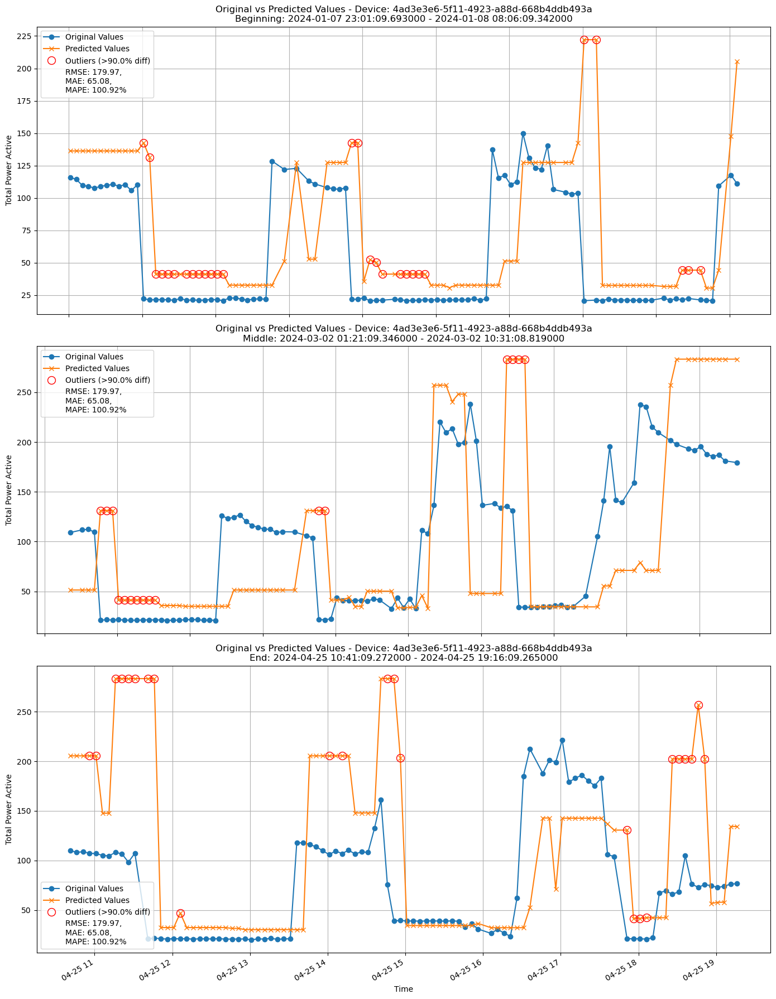

In [ ]:
for device_id in fodt_train_period_predictions.keys():
    print(f"\n\nDevice ID: {device_id}")
    print("-"*10)
    y_train = fodt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = fodt_train_period_predictions[device_id][-1]['y_pred']
    plot_part_predictions(y_train, y_pred_train, data_show=100, device_id=device_id)
    print("="*25)

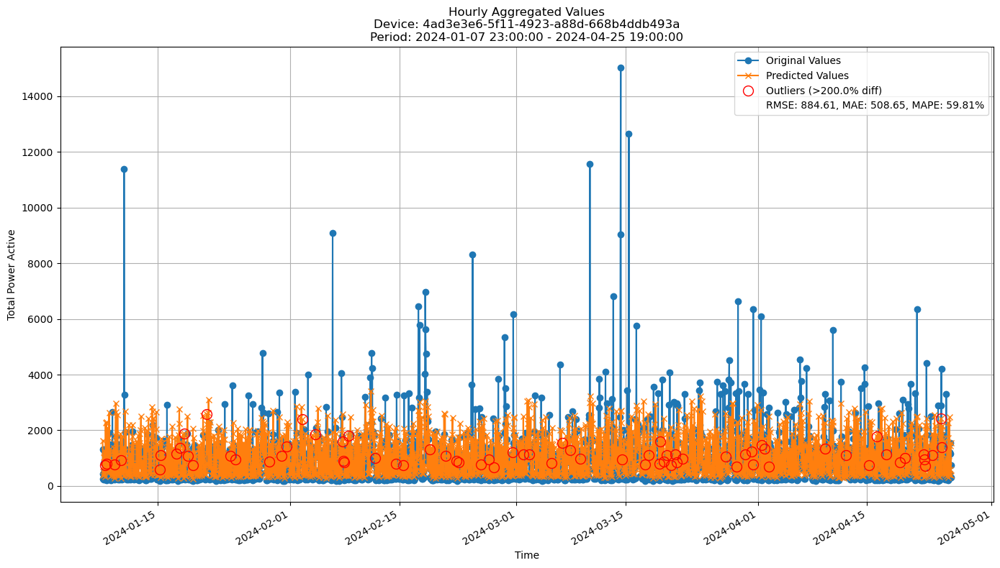

In [ ]:
for device_id in fodt_train_period_predictions.keys():
    y_train = fodt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = fodt_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=0.9)

#### Validation plots
Plot only the last period of predictions

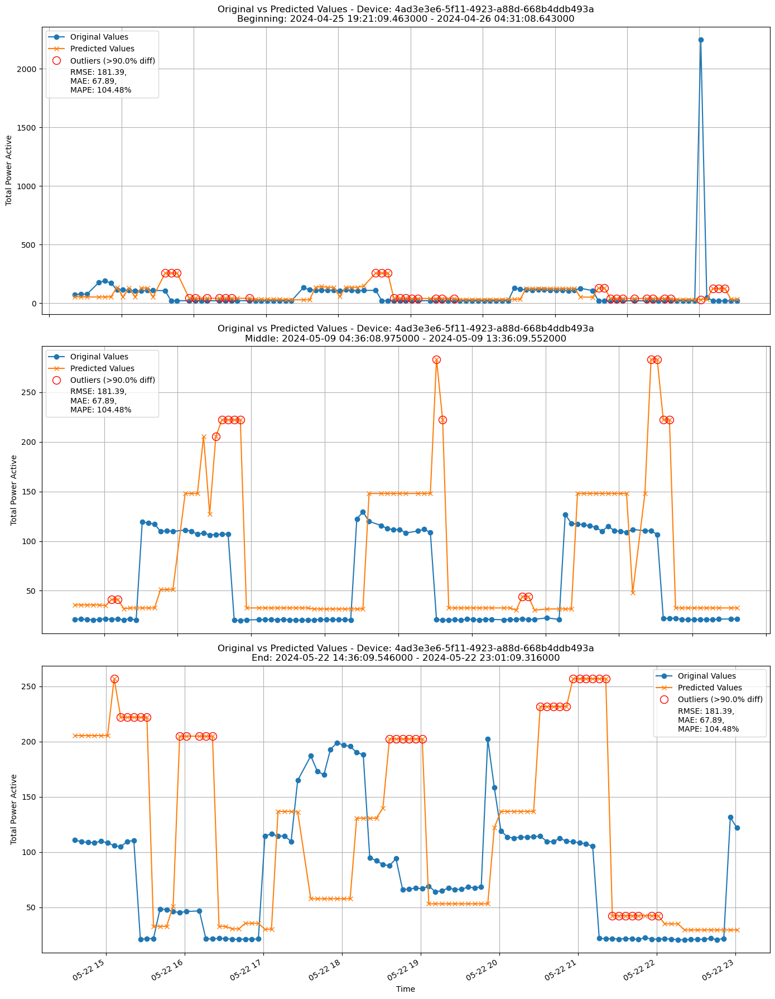

In [ ]:
for device_id in fodt_valid_period_predictions.keys():
    print(f"\n\nDevice ID: {device_id}")
    print("-"*10)
    y_valid = fodt_valid_period_predictions[device_id][-1]['y_true']
    y_pred_valid = fodt_valid_period_predictions[device_id][-1]['y_pred']
    plot_part_predictions(y_valid, y_pred_valid, data_show=100, device_id=device_id)
    print("="*25)

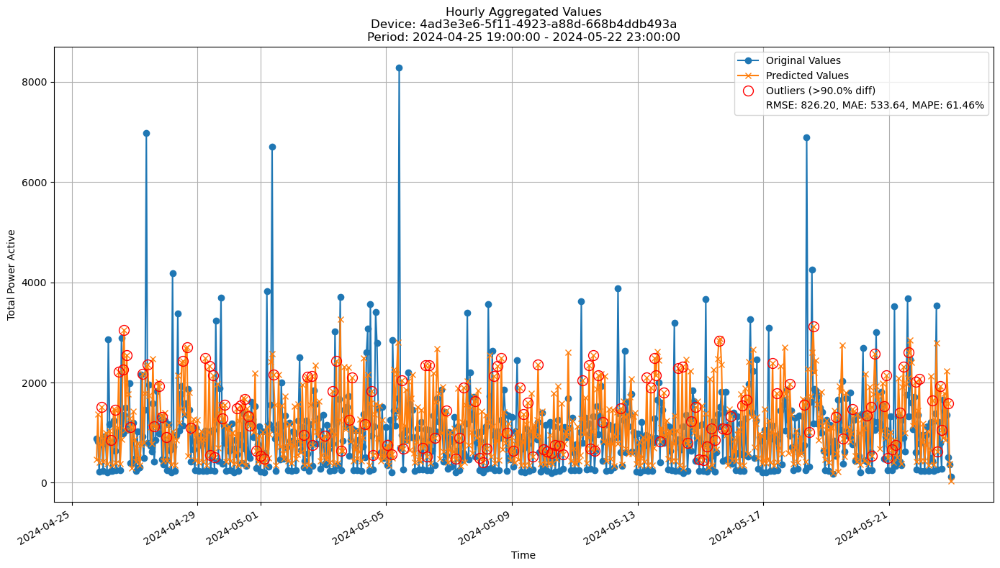

In [ ]:
for device_id in fodt_valid_period_predictions.keys():
    y_valid = fodt_valid_period_predictions[device_id][-1]['y_true']
    y_pred_valid = fodt_valid_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=0.9)

### iNcubation Boost

In [ ]:
update_freq = "5m"  # for incremental models put the same as the data frequency to recreate real world scenario
split_confidence_hf = 0.05
n_trees = 5
depth = 20
grace_period = 10
incb = IncubationBoost(
    fastodt.FastODT,
    n_trees,
    incubationMode = "SHIFT_LEFT",
    baseLearnerOptions = (depth, grace_period, split_confidence_hf, "hf")
    )

incb_train_period_predictions, incb_valid_period_predictions, \
incb_train_period_metrics, incb_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model=incb, 
    train=train, 
    valid=valid, 
    incremental=True, 
    update_freq=update_freq, 
    start_split=2, 
    end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 2:   0%|          | 0/8 [00:00<?, ?it/s]

Initial training on data from 2024-01-07 23:00:51.612000 to 2024-03-29 10:40:50.850000
Train predictions completed.
Metrics for Device: dd40019b-5b35-4fba-b0dd-16083c1fdb84 | Period: 2024-03-29 10:45:51.165000 - 2024-04-25 19:20:51.376000
5-Minute Metrics:
--------------------------------------------------
	RMSE: 90.9151
	MAE: 17.9317
	MAPE: 79.4546%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 467.3731
	MAE: 91.9092
	MAPE: 17.7618%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2405.1208
	MAE: 1049.6517
	MAPE: 9.3960%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 7591.0264
	MAE: 5747.9153
	MAPE: 11.0826%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 2346.5650
	MAE: 2346.5650

Processing devices in split 3:   0%|          | 0/8 [00:00<?, ?it/s]

Initial training on data from 2024-01-07 23:00:51.612000 to 2024-04-25 19:20:51.376000
Train predictions completed.
Metrics for Device: dd40019b-5b35-4fba-b0dd-16083c1fdb84 | Period: 2024-04-25 19:25:50.519000 - 2024-05-22 23:00:51.240000
5-Minute Metrics:
--------------------------------------------------
	RMSE: 172.9277
	MAE: 60.4105
	MAPE: 114.0333%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 896.5167
	MAE: 404.7263
	MAPE: 56.8194%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 5542.0328
	MAE: 4441.6231
	MAPE: 27.3677%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 24897.8928
	MAE: 21982.5180
	MAPE: 23.4405%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 109912.5898
	MAE: 1

In [ ]:
print("\n\nTrain period metrics:")
all_time_train_metrics = all_time_aggregation_metrics(incb_train_period_metrics, verbose=True)
print("\n\Valid period metrics:")
all_time_valid_metrics = all_time_aggregation_metrics(incb_valid_period_metrics, verbose=True)

#### Train plots
Plot only the last period of predictions


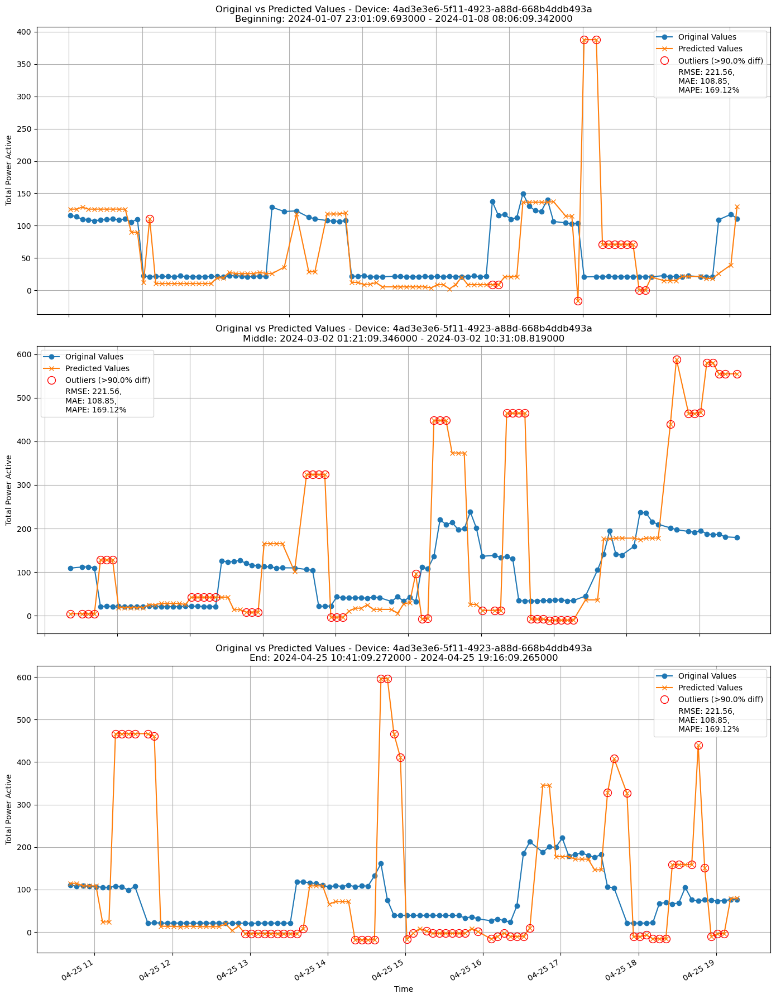

In [ ]:
for device_id in incb_train_period_predictions.keys():
    print(f"\n\nDevice ID: {device_id}")
    print("-"*10)
    y_train = incb_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = incb_train_period_predictions[device_id][-1]['y_pred']
    plot_part_predictions(y_train, y_pred_train, data_show=100, device_id=device_id)
    print("="*25)


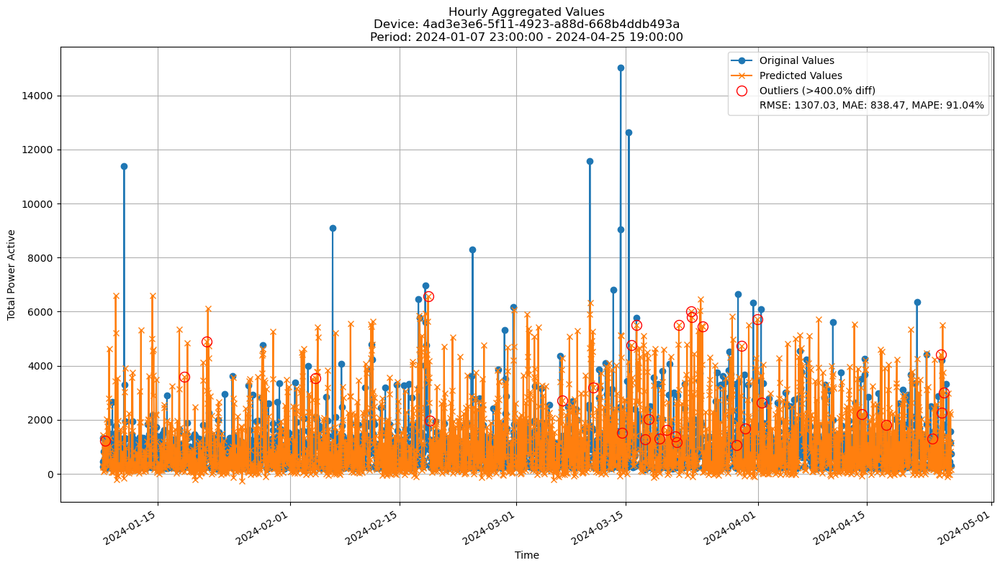

In [ ]:
for device_id in incb_train_period_predictions.keys():
    y_train = incb_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = incb_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=0.9)

#### Validation plots
Plot only the last period of predictions

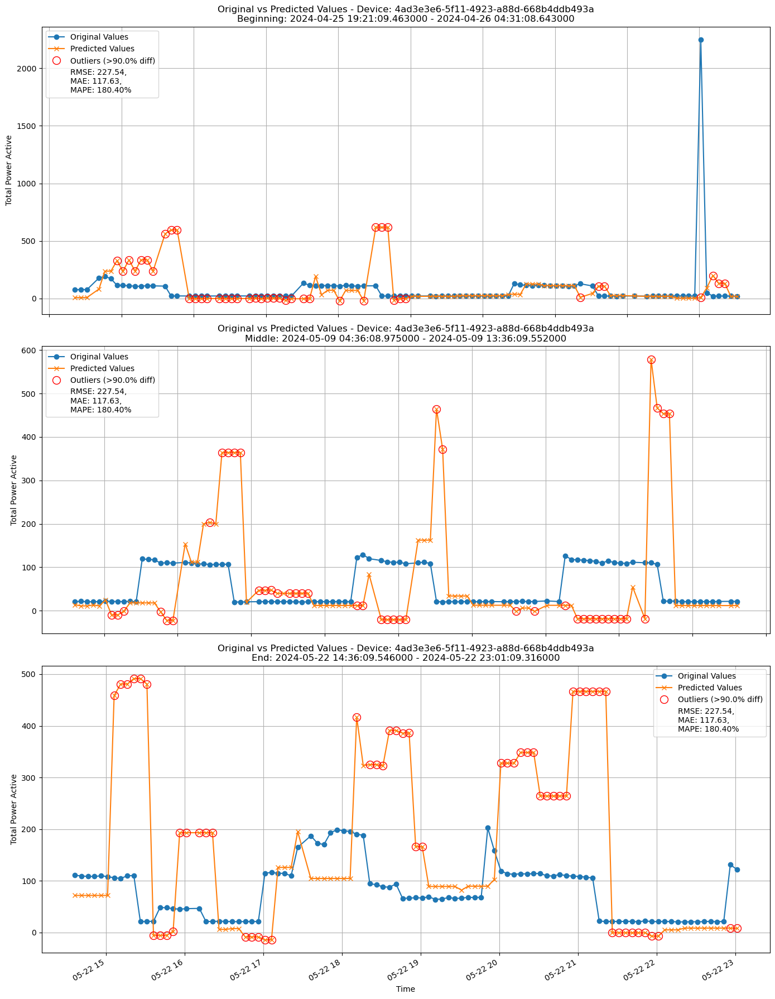

In [ ]:
for device_id in incb_valid_period_predictions.keys():
    print(f"\n\nDevice ID: {device_id}")
    print("-"*10)
    y_valid = incb_valid_period_predictions[device_id][-1]['y_true']
    y_pred_valid = incb_valid_period_predictions[device_id][-1]['y_pred']
    plot_part_predictions(y_valid, y_pred_valid, data_show=100, device_id=device_id)
    print("="*25)

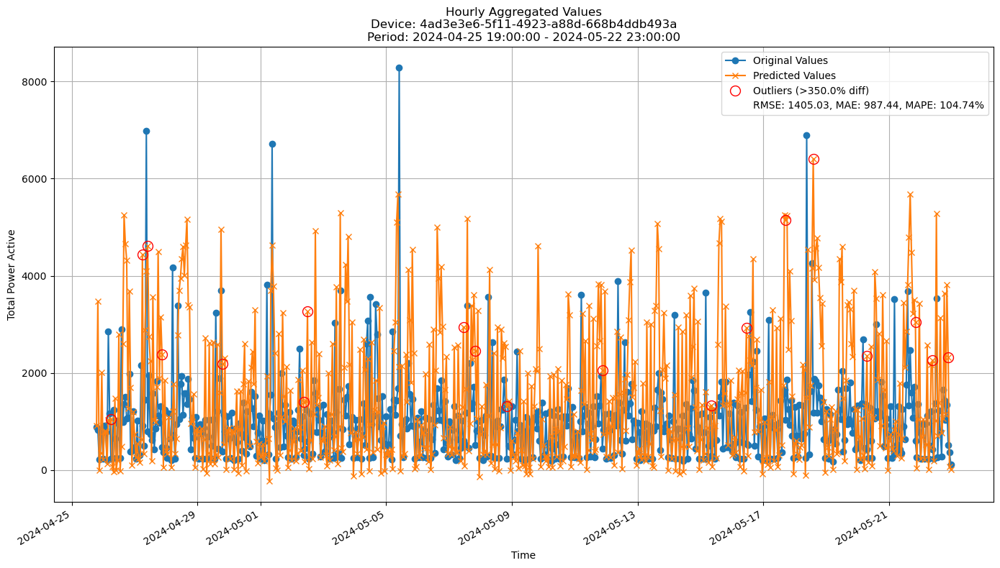

In [ ]:
for device_id in incb_valid_period_predictions.keys():
    y_valid = incb_valid_period_predictions[device_id][-1]['y_true']
    y_pred_valid = incb_valid_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=0.9)

## Hourly granularity

### Baseline model (predict previous value)

In [9]:
device_period_metrics = {}
for split in valid:
    for device_id in set(split[0][:, 1]):  # Assuming device_id is in the second column
        X_valid, y_valid = get_device_data(split, device_id=device_id)
        y_pred = y_valid.shift(1)
        y_pred.iloc[0] = y_valid.iloc[0]
        
        device_metrics = calculate_metrics(
            y_valid,
            y_pred,
            device_id,
            f"{X_valid[0, 0]} - {X_valid[-1, 0]}", 
            verbose=True
            )
        
        if device_id not in device_period_metrics:
            device_period_metrics[device_id] = []
        device_period_metrics[device_id].append(device_metrics)

all_time_metrics = all_time_aggregation_metrics(device_period_metrics, verbose=True)


Metrics for Device: 4a448440-d2dd-4b27-ae02-87e7e3baa9f5 | Period: 2024-02-03 11:00:00 - 2024-03-01 21:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 342.5868
	MAE: 148.8698
	MAPE: 78.7610%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 342.5868
	MAE: 148.8698
	MAPE: 78.7610%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 52.1276
	MAE: 23.6018
	MAPE: 0.8729%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 112.0562
	MAE: 71.4903
	MAPE: 0.6350%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 273.1459
	MAE: 273.1459
	MAPE: 0.2363%
Metrics for Device: f90e7387-9810-408d-885b-6f3841f4ec3f | Period: 2024-02-03 10:00:00 - 2024-03-01 21:00:00
5-Minute Met

#### Validation plots

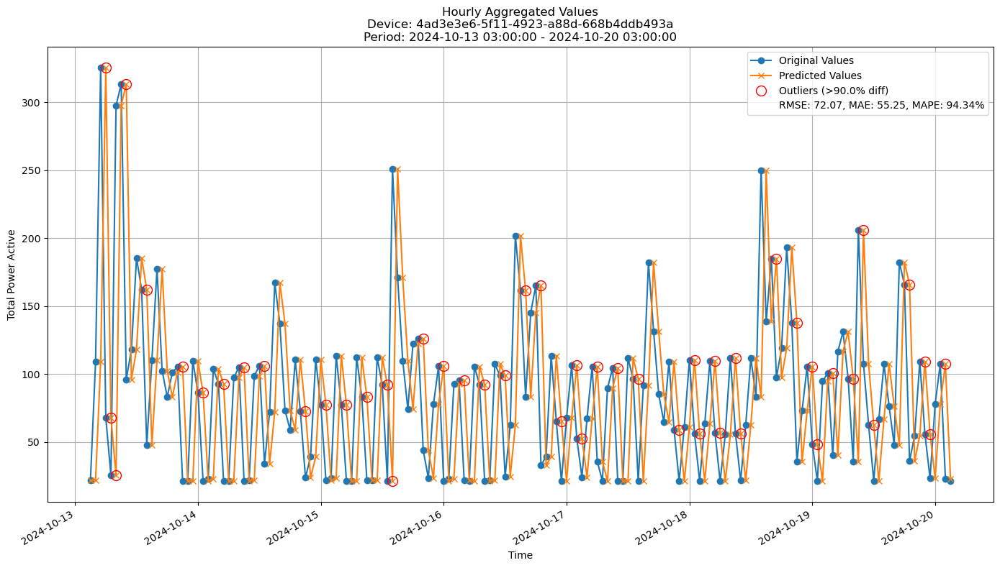

In [ ]:
plot_hourly_predictions(X_valid, 
                        y_valid, 
                        y_pred, 
                        device_id=device_id, 
                        outlier_threshold=0.9)

### GBDT

In [ ]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor(
    n_estimators=125,
    learning_rate=0.01,
    subsample=0.8,
    max_depth=4,
    random_state=42)

gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model=gbdt, 
    train=train, 
    valid=valid, 
    incremental=False, 
    update_freq=update_freq, 
    start_split=2, 
    end_split=4,  # Use only the third and fourth splits
    verbose=False
)

In [ ]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, verbose=True)
print("\n\n\Valid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: a4b80cd7-5438-44cd-8257-c9ac81684822
--------------------------------------------------
5_min Metrics:
	RMSE: 14.2308 ± 5.6155
	MAE: 8.5194 ± 2.6331
	MAPE: 0.0192 ± 0.0074
Hourly Metrics:
	RMSE: 14.2308 ± 5.6155
	MAE: 8.5194 ± 2.6331
	MAPE: 0.0192 ± 0.0074
Daily Metrics:
	RMSE: 88.3008 ± 37.3514
	MAE: 66.4794 ± 26.4192
	MAPE: 0.0056 ± 0.0025
Weekly Metrics:
	RMSE: 252.9779 ± 107.3517
	MAE: 192.5814 ± 79.8318
	MAPE: 0.0028 ± 0.0011
28_days Metrics:
	RMSE: 184.8134 ± 95.5074
	MAE: 176.3731 ± 92.8477
	MAPE: 0.0005 ± 0.0003
Device ID: 4a448440-d2dd-4b27-ae02-87e7e3baa9f5
--------------------------------------------------
5_min Metrics:
	RMSE: 159.1366 ± 5.4853
	MAE: 94.3195 ± 2.9242
	MAPE: 0.8379 ± 0.0373
Hourly Metrics:
	RMSE: 159.1366 ± 5.4853
	MAE: 94.3195 ± 2.9242
	MAPE: 0.8379 ± 0.0373
Daily Metrics:
	RMSE: 958.6107 ± 31.7141
	MAE: 790.8049 ± 29.3608
	MAPE: 0.2645 ± 0.0071
Weekly Metrics:
	RMSE: 1815.0934 ± 125.612

#### Feature importance
[WiP] Right now only for the last split and last device

In [14]:
feat_imps = sorted(
    zip(features[2:], gbdt.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


[('total_power_reactive_lag_1h', 0.10722061605156231),
 ('hour', 0.09136263052449668),
 ('total_power_apparent_lag_24h', 0.08161525811711717),
 ('total_power_reactive_lag_168h', 0.06722537328444998),
 ('total_power_active_lag_24h', 0.06457956744321289),
 ('total_power_active_lag_1h', 0.05594628115022836),
 ('import_energy_active_lag_168h', 0.05191897123775874),
 ('total_power_apparent_lag_1h', 0.050256514464879526),
 ('total_power_reactive_lag_24h', 0.04757463373243297),
 ('import_energy_reactive_lag_24h', 0.044840900086552615),
 ('total_power_apparent_lag_168h', 0.043923233002224754),
 ('import_energy_reactive_lag_168h', 0.040039252026493964),
 ('total_power_active_lag_168h', 0.034767117124981525),
 ('total_energy_active_lag_24h', 0.030854234079655384),
 ('export_energy_reactive_lag_1h', 0.02756716798413736),
 ('total_energy_reactive_lag_24h', 0.02338025224927232),
 ('weekday', 0.021506156162734838),
 ('total_energy_active_lag_1h', 0.020602542137562446),
 ('import_energy_reactive_lag_

#### Training plots
Plot only the last period of predictions

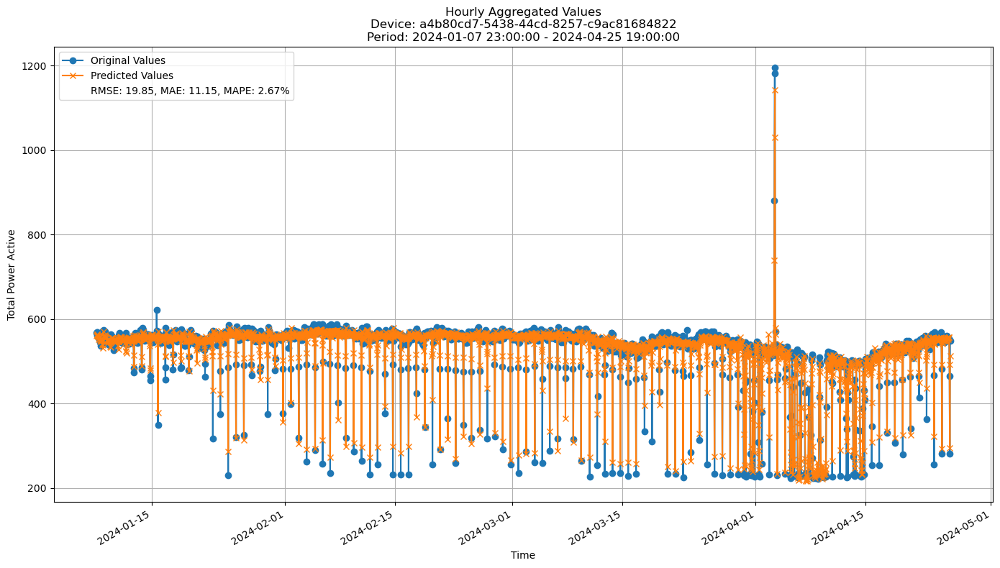

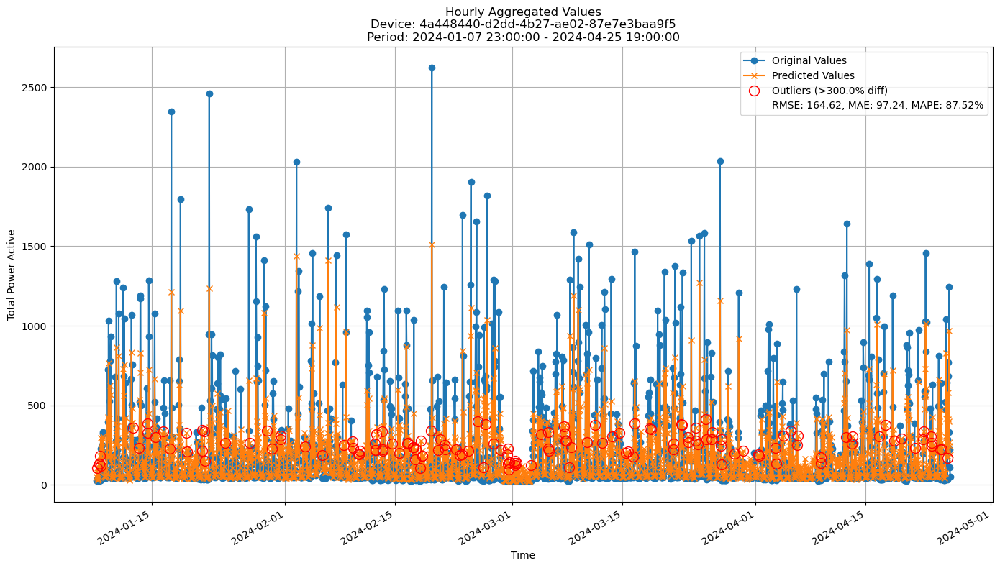

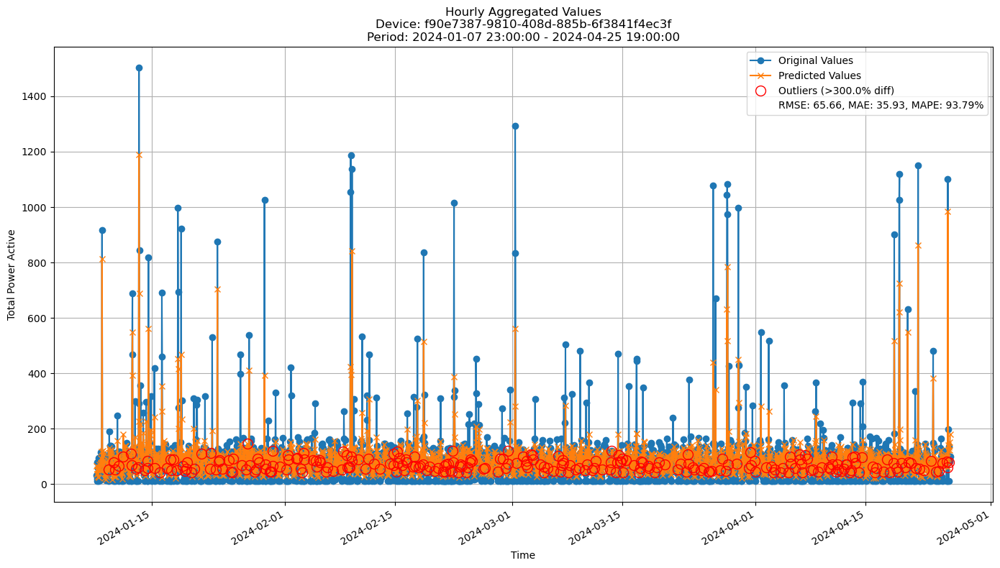

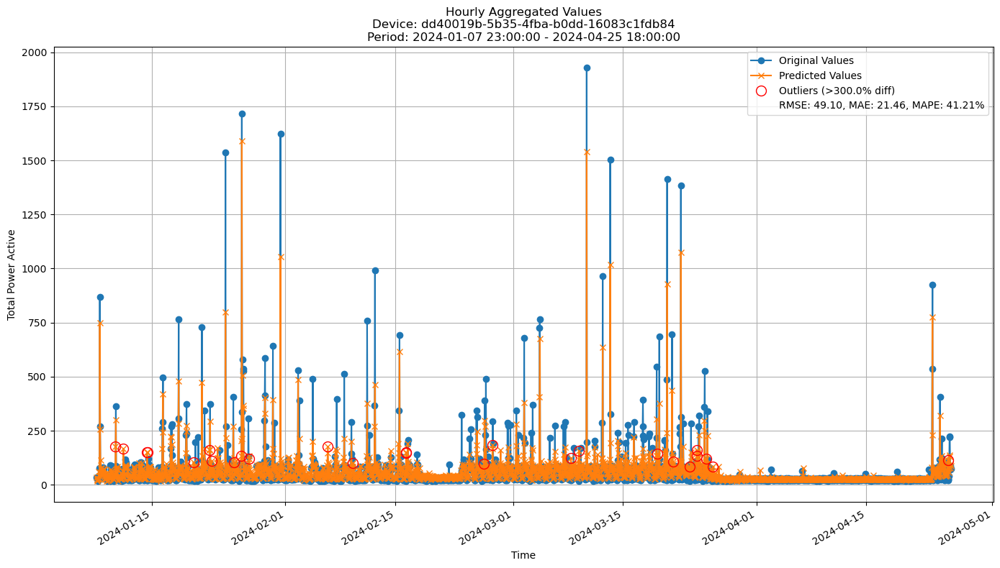

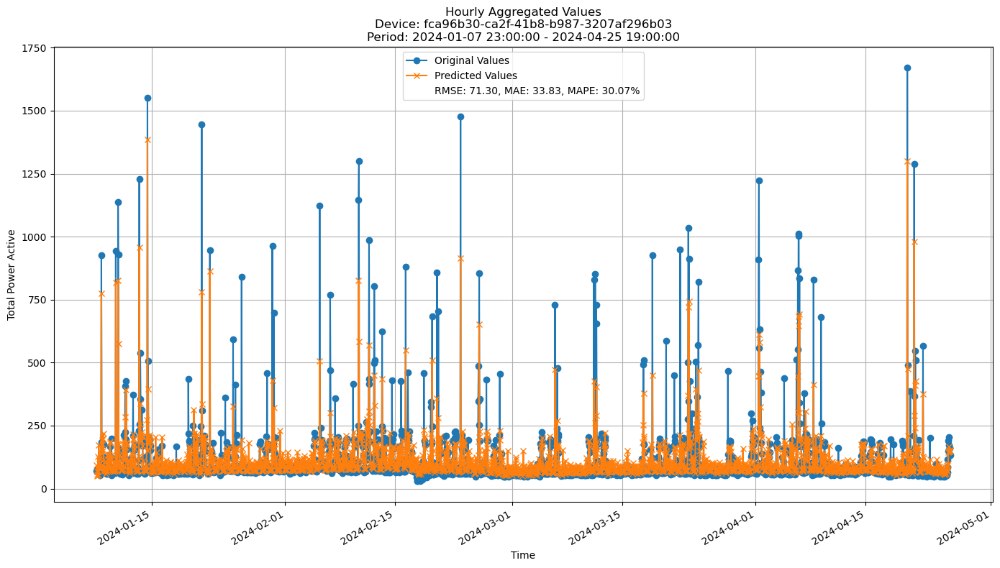

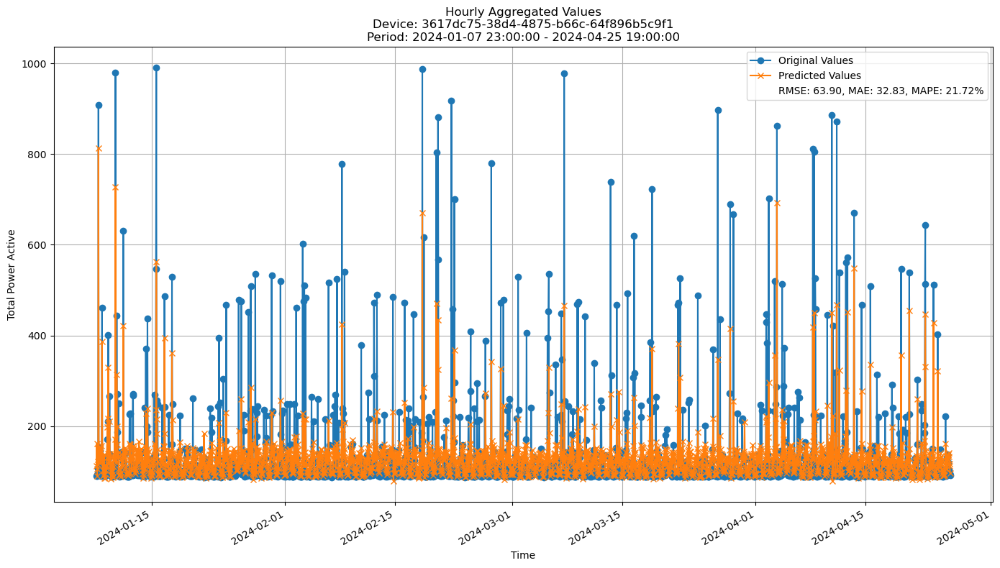

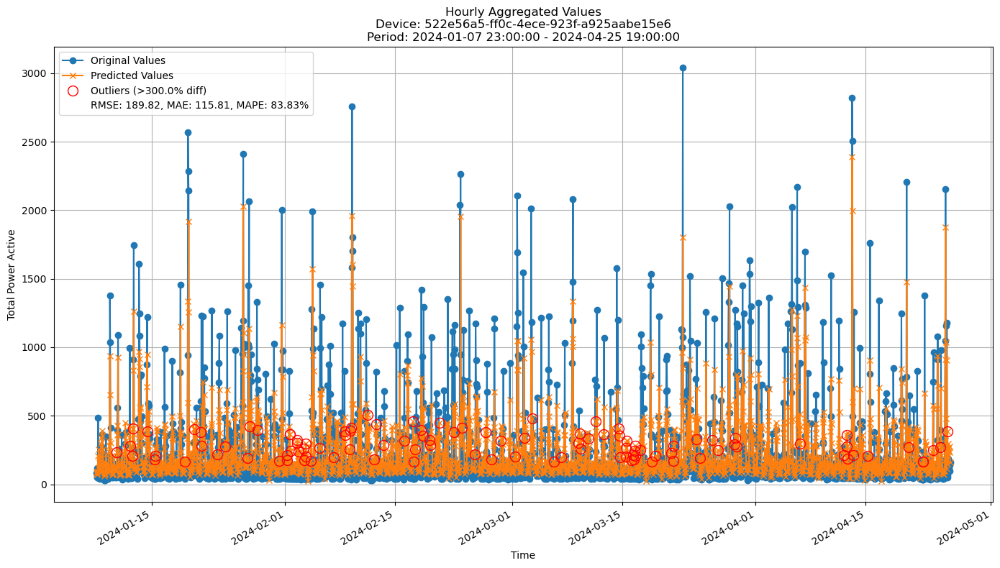

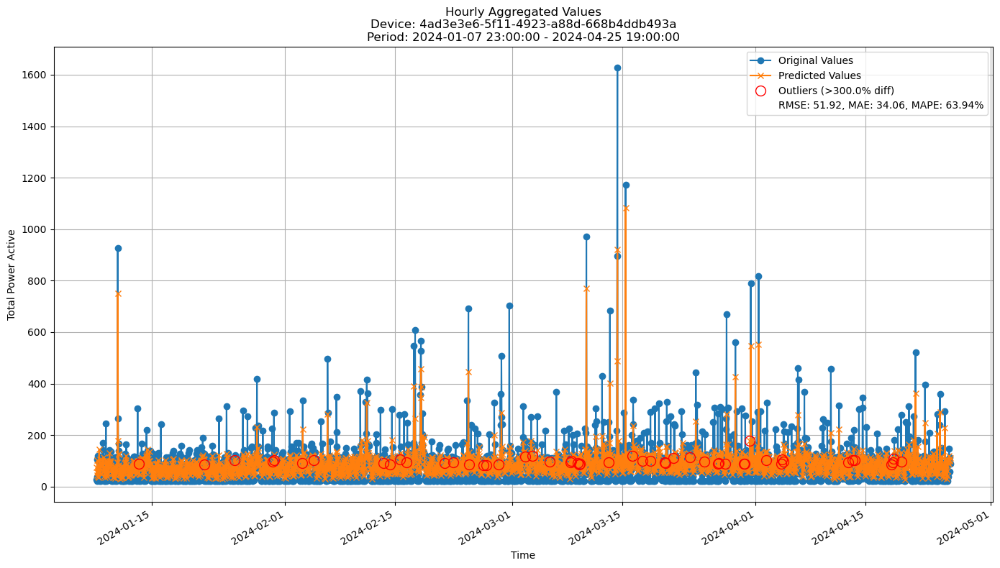

In [15]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=3.0)
# 48, 32, 61

#### Validation plots
Plot only the last period of predictions

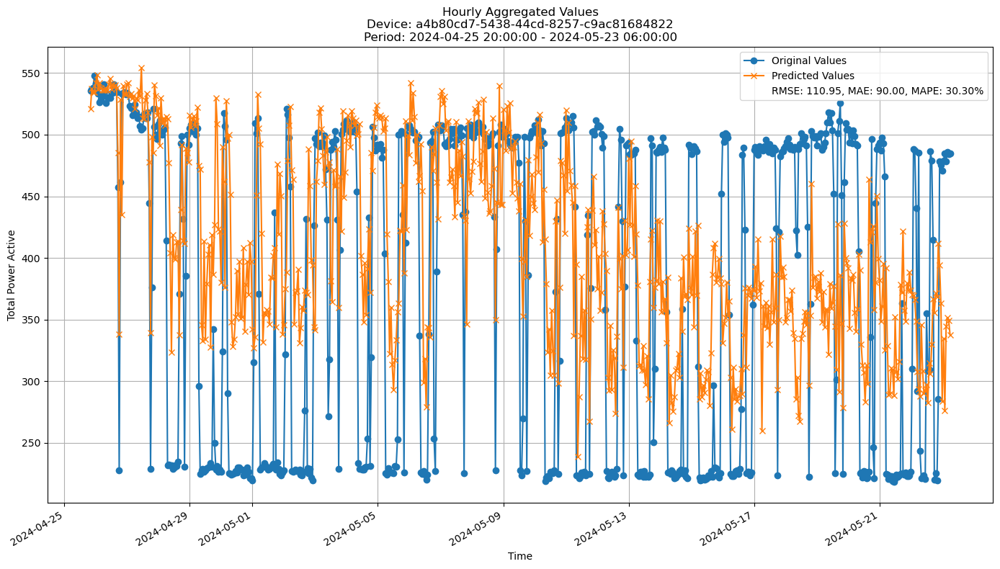

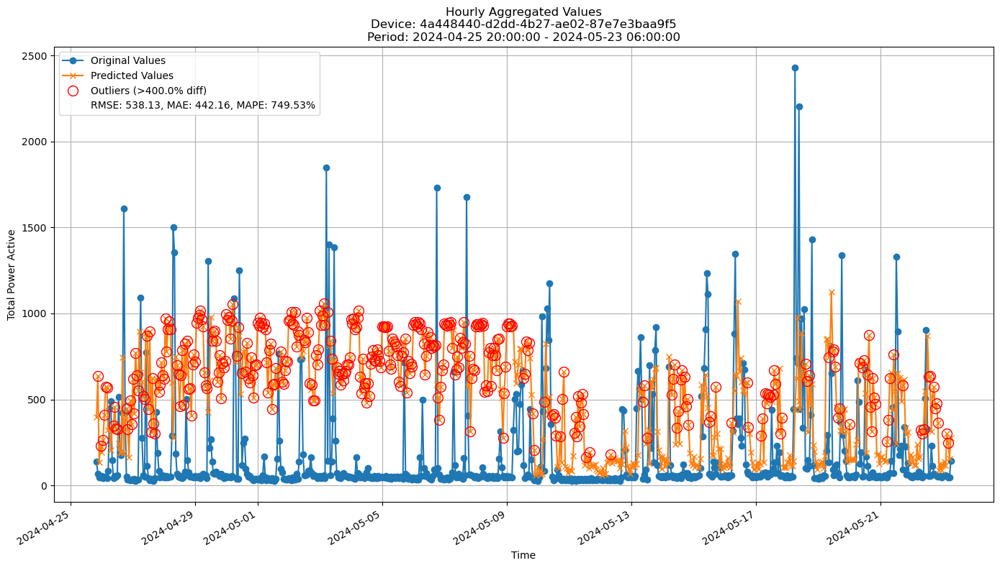

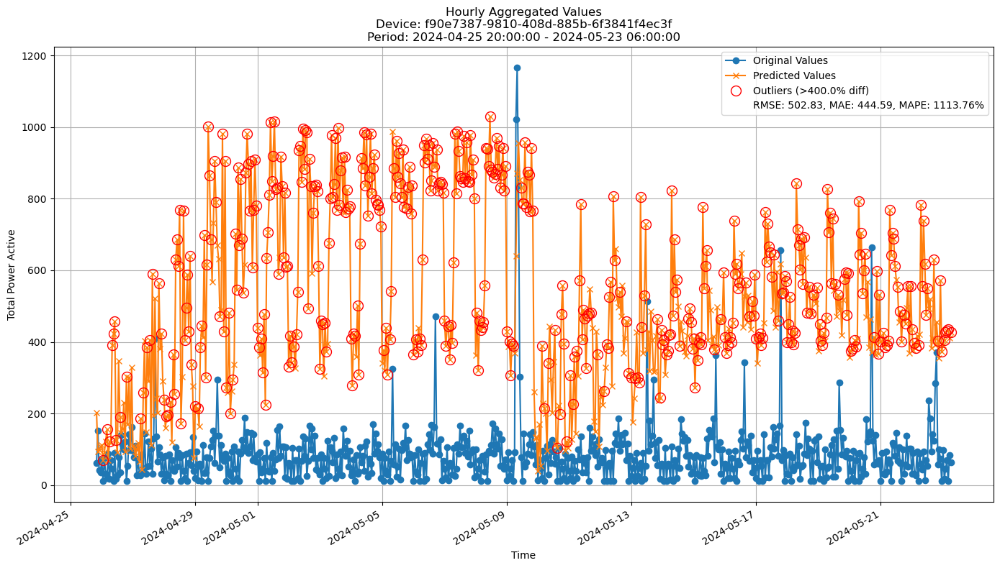

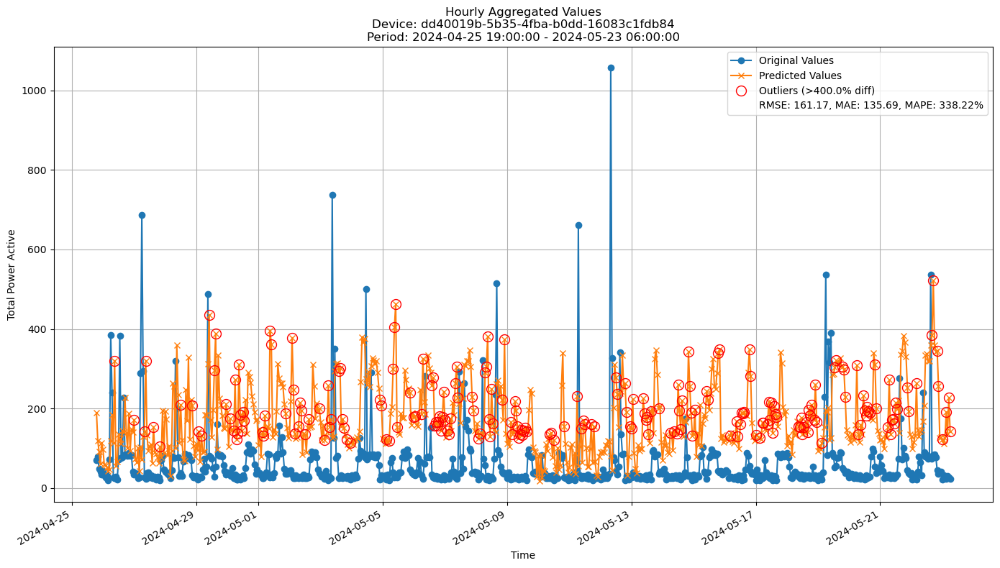

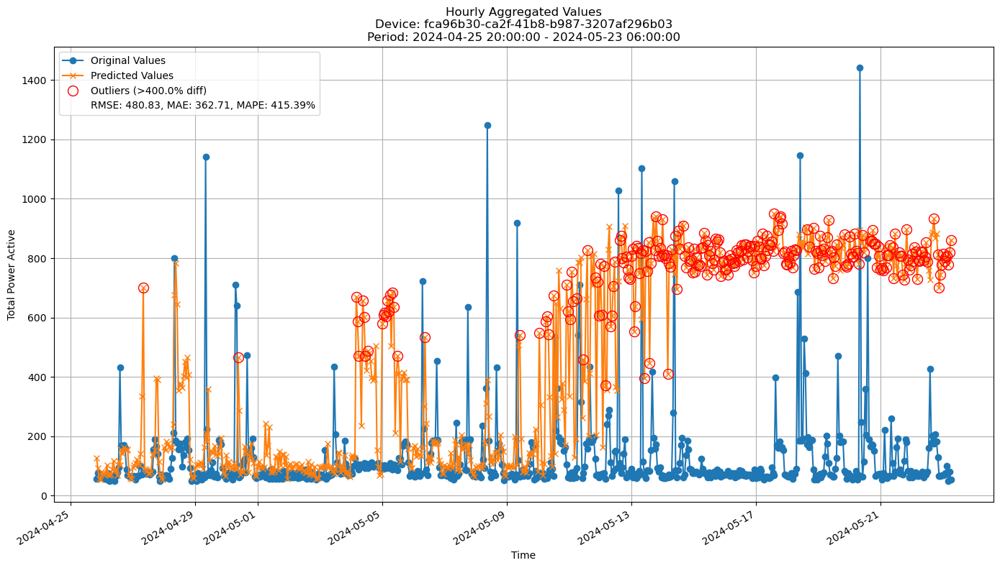

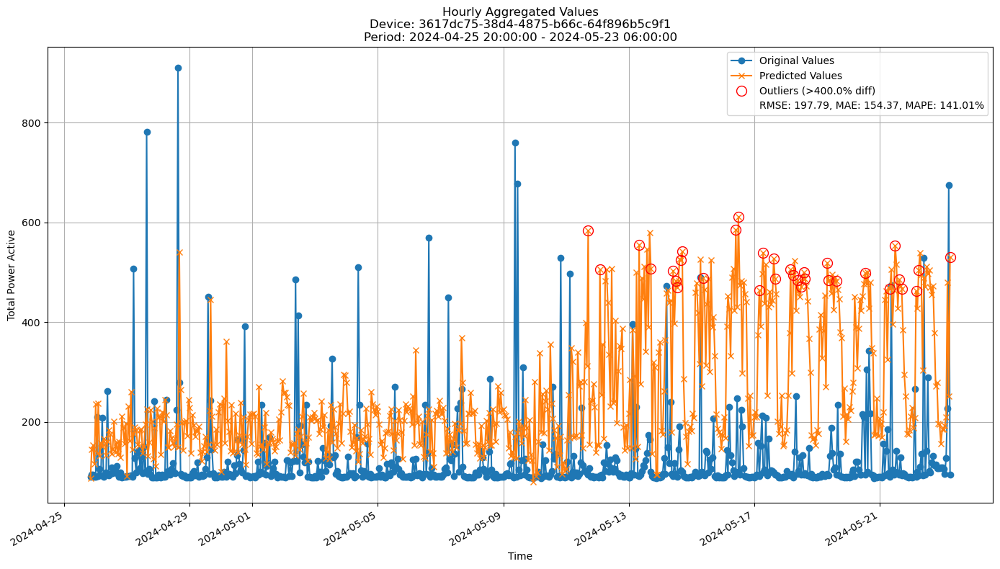

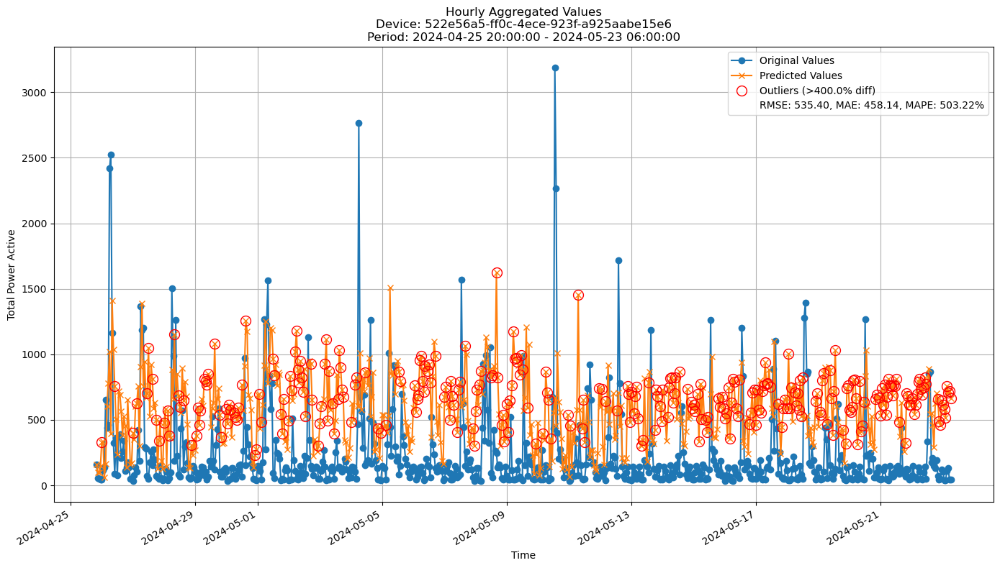

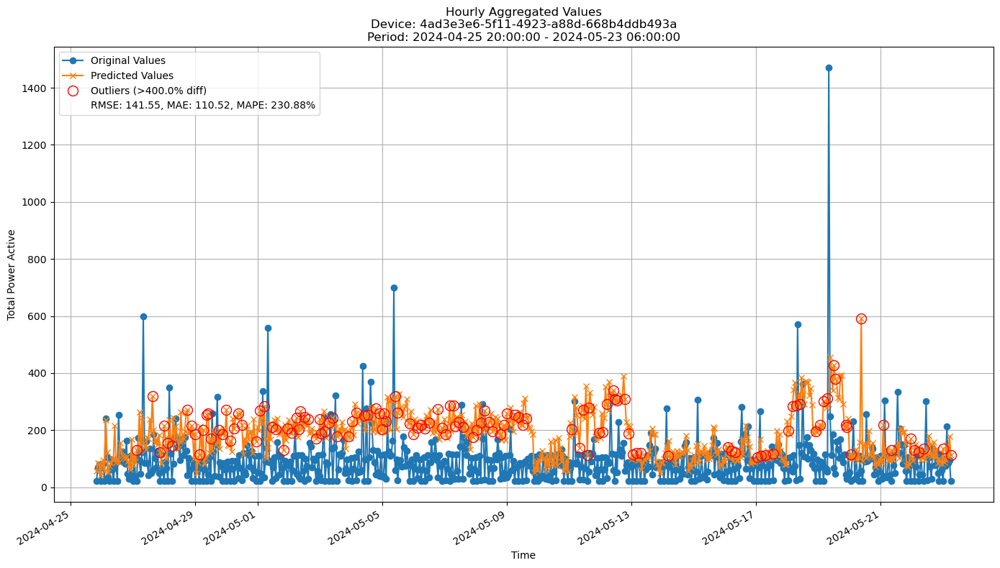

In [16]:
for device_id in gbdt_valid_period_predictions.keys():
    
    y_valid = gbdt_valid_period_predictions[device_id][-1]['y_true']
    y_pred_valid = gbdt_valid_period_predictions[device_id][-1]['y_pred']

    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=4.)
# 145 115 240

### Random Forest model

In [ ]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor(
    n_estimators=100, 
    max_depth=4,
    max_features=0.8,
    random_state=42, 
    n_jobs=-1)

rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model=rf, 
    train=train, 
    valid=valid, 
    incremental=False, 
    update_freq=update_freq, 
    start_split=2, 
    end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 2:   0%|          | 0/8 [00:00<?, ?it/s]


Retraining model on data from 2024-01-07 23:00:00 to 2024-03-29 08:00:00

Time: 0.34 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2024-03-29 09:00:00 to 2024-04-12 09:00:00

-------------------------

Retraining model on data from 2024-01-07 23:00:00 to 2024-04-12 09:00:00

Time: 0.36 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2024-04-12 10:00:00 to 2024-04-25 19:00:00

-------------------------
Metrics for Device: 4ad3e3e6-5f11-4923-a88d-668b4ddb493a | Period: 2024-03-29 09:00:00 - 2024-04-25 19:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 98.4038
	MAE: 73.7861
	MAPE: 163.0937%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 98.4038
	MAE: 73.7861
	MAPE: 163.0937%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	

Processing devices in split 3:   0%|          | 0/8 [00:00<?, ?it/s]


Retraining model on data from 2024-01-07 23:00:00 to 2024-04-25 19:00:00

Time: 0.44 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2024-04-25 20:00:00 to 2024-05-09 20:00:00

-------------------------

Retraining model on data from 2024-01-07 23:00:00 to 2024-05-09 20:00:00

Time: 0.47 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2024-05-09 21:00:00 to 2024-05-23 06:00:00

-------------------------
Metrics for Device: 4ad3e3e6-5f11-4923-a88d-668b4ddb493a | Period: 2024-04-25 20:00:00 - 2024-05-23 06:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 93.4235
	MAE: 54.0861
	MAPE: 108.8289%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 93.4235
	MAE: 54.0861
	MAPE: 108.8289%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	

In [15]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, verbose=True)
print("\n\Valid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: 4ad3e3e6-5f11-4923-a88d-668b4ddb493a
--------------------------------------------------
5_min Metrics:
	RMSE: 73.3636 ± 1.1497
	MAE: 41.7540 ± 0.5109
	MAPE: 0.7924 ± 0.0039
Hourly Metrics:
	RMSE: 73.3636 ± 1.1497
	MAE: 41.7540 ± 0.5109
	MAPE: 0.7924 ± 0.0039
Daily Metrics:
	RMSE: 404.1925 ± 17.5587
	MAE: 284.8857 ± 15.8434
	MAPE: 0.1616 ± 0.0012
Weekly Metrics:
	RMSE: 1500.9306 ± 97.1361
	MAE: 1043.5697 ± 87.5404
	MAPE: 0.2627 ± 0.0463
28_days Metrics:
	RMSE: 4156.4084 ± 408.4335
	MAE: 3395.2818 ± 18.3227
	MAPE: 0.0608 ± 0.0013
Device ID: dd40019b-5b35-4fba-b0dd-16083c1fdb84
--------------------------------------------------
5_min Metrics:
	RMSE: 89.3102 ± 5.4294
	MAE: 34.2109 ± 3.6309
	MAPE: 0.6052 ± 0.0574
Hourly Metrics:
	RMSE: 89.3102 ± 5.4294
	MAE: 34.2109 ± 3.6309
	MAPE: 0.6052 ± 0.0574
Daily Metrics:
	RMSE: 435.8387 ± 28.1798
	MAE: 316.1358 ± 39.0329
	MAPE: 0.2220 ± 0.0312
Weekly Metrics:
	RMSE: 1057.5891 ± 8

#### Training plots
Plot only the last period of predictions

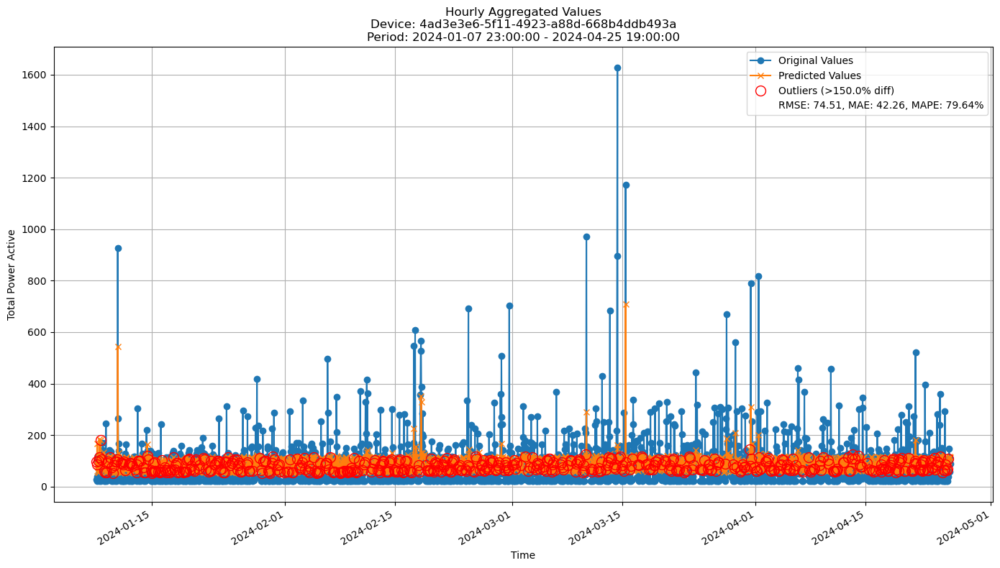

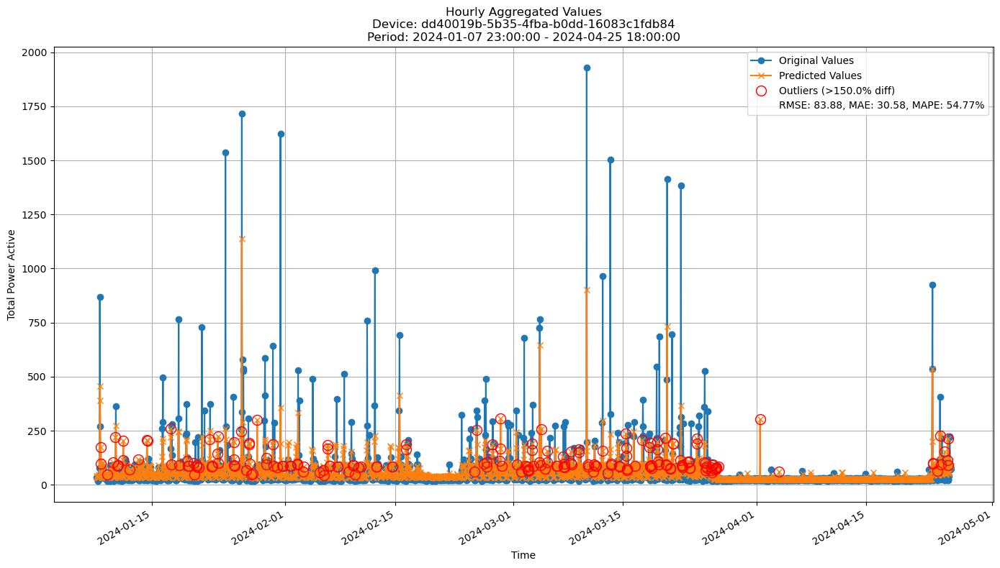

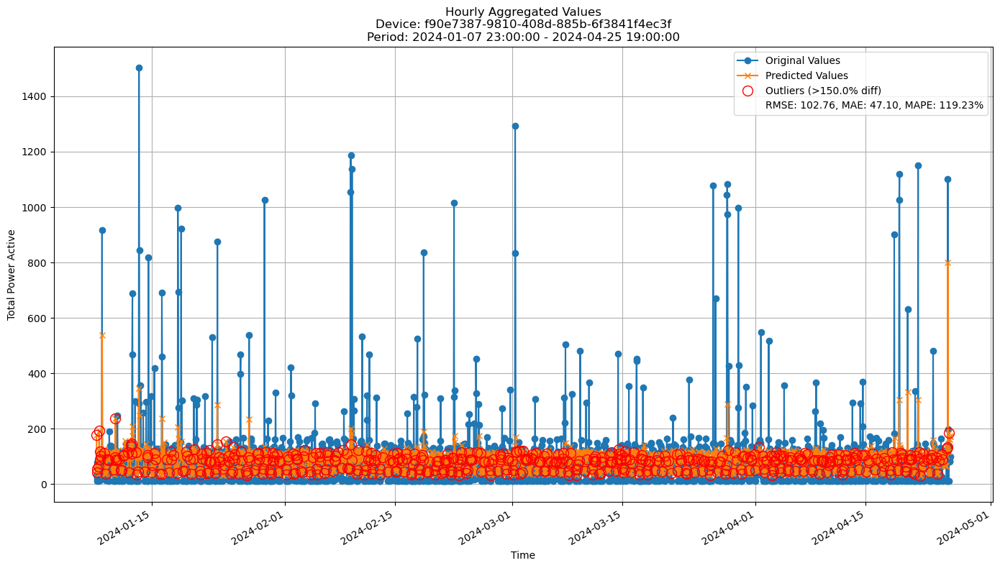

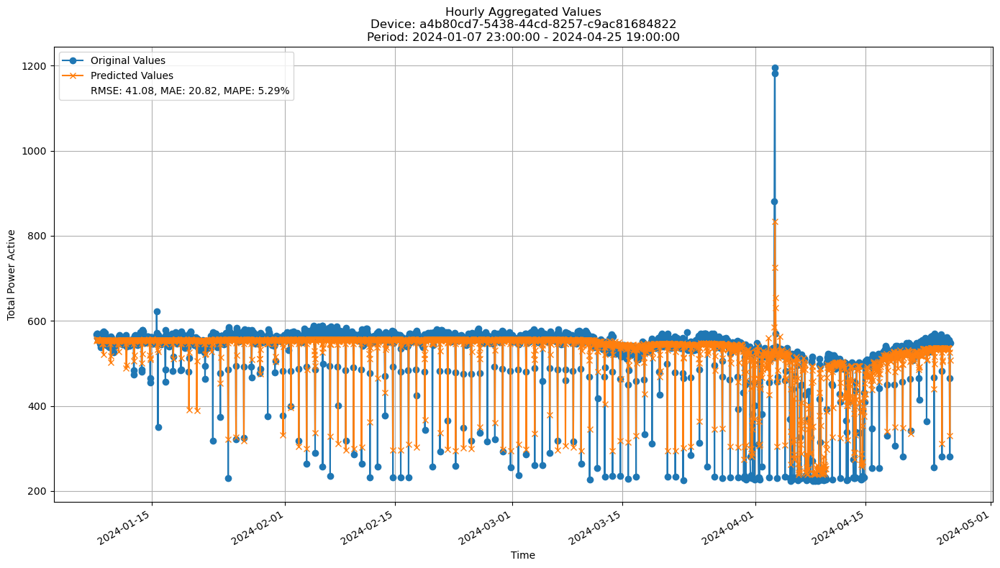

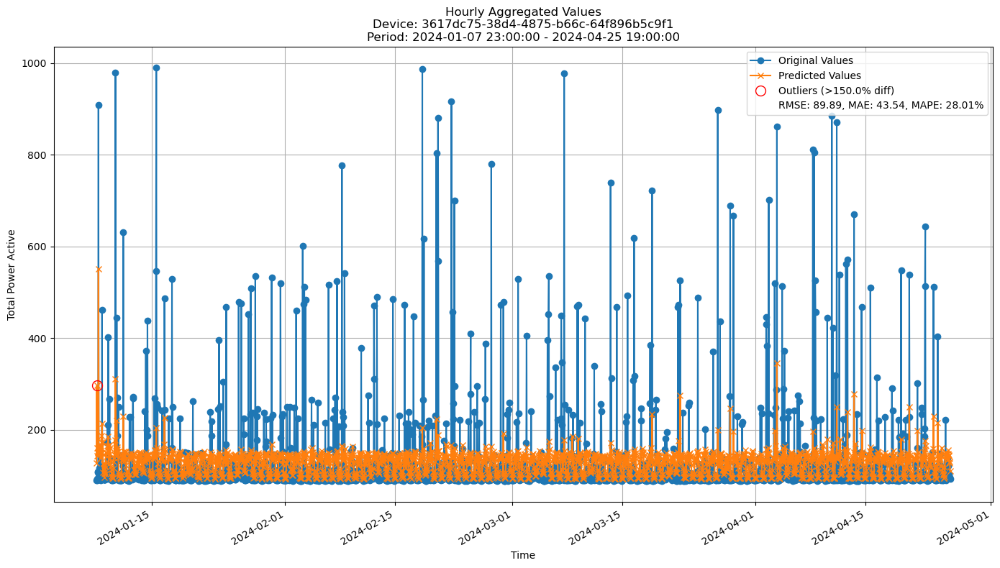

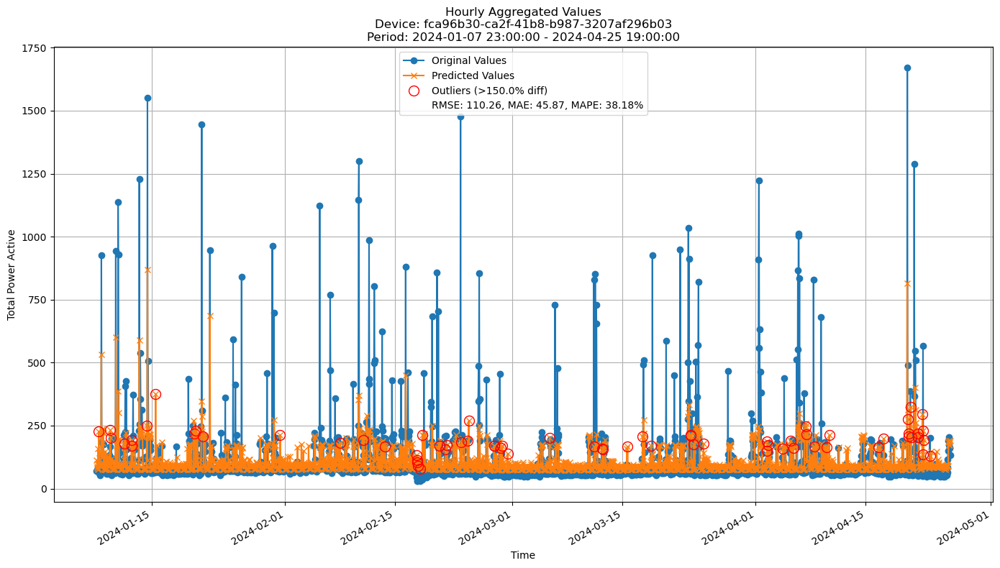

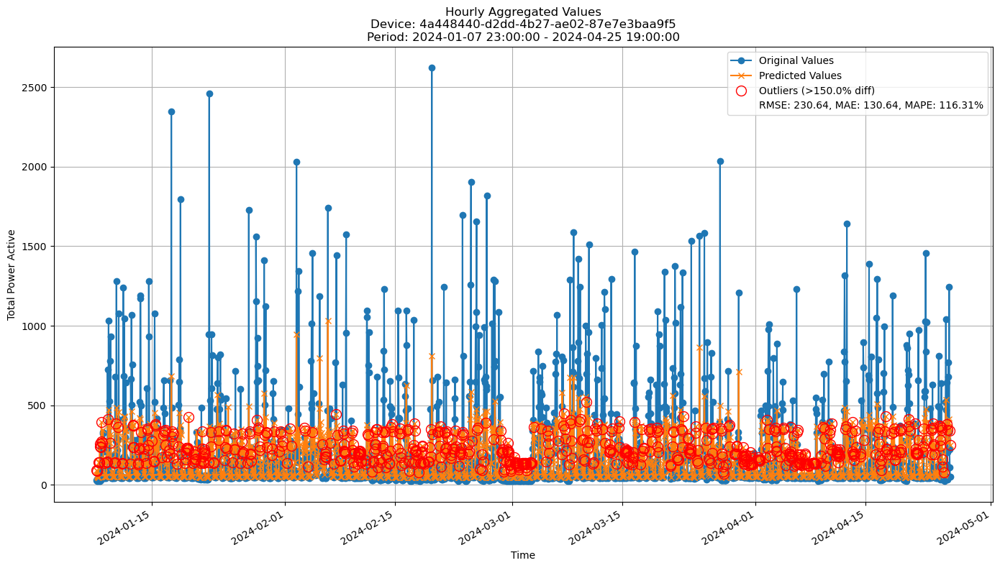

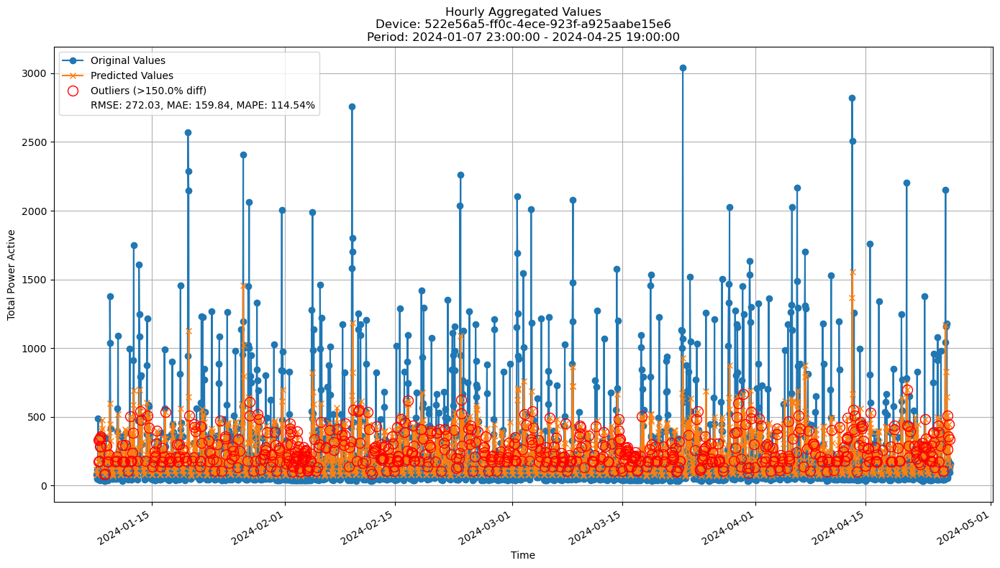

In [28]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

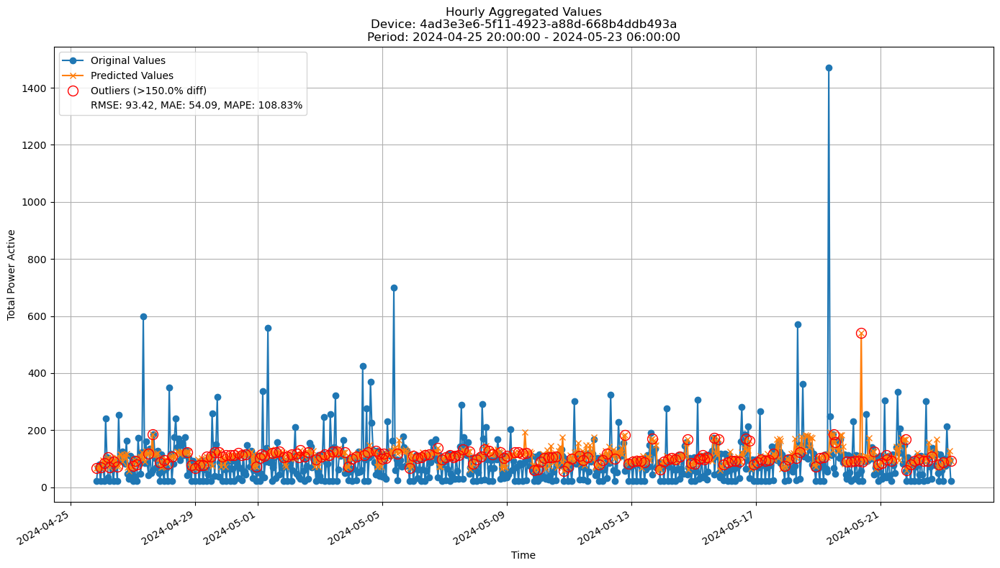

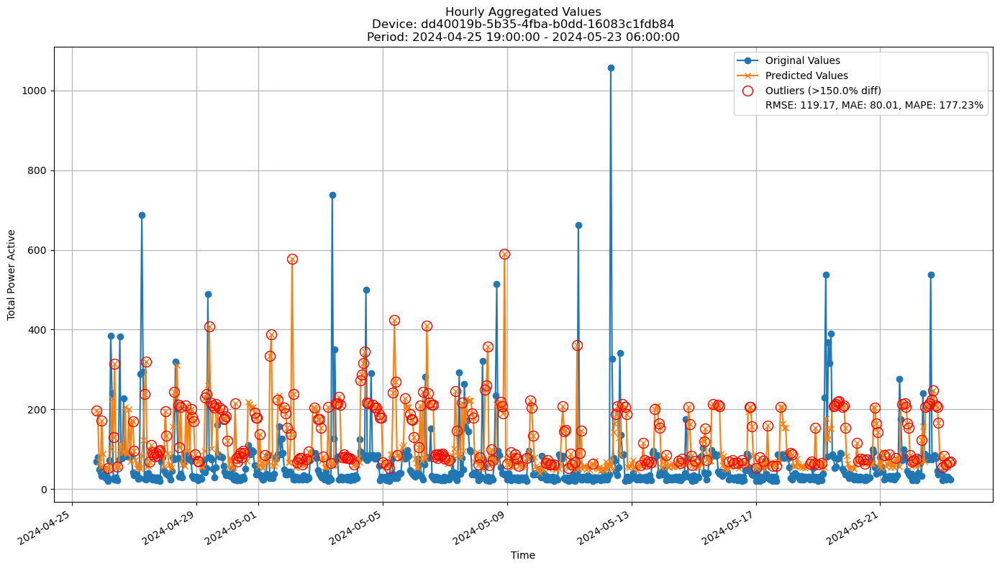

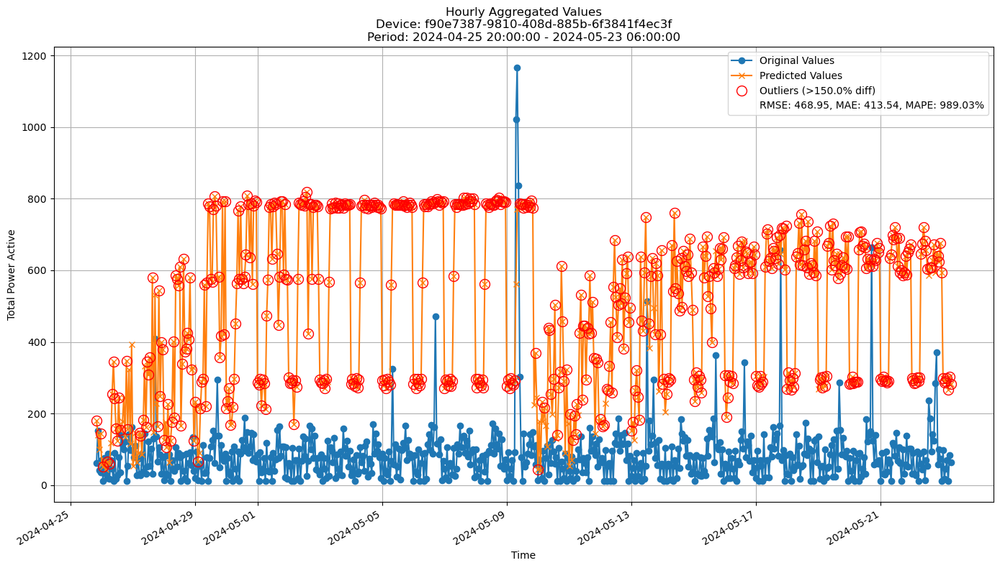

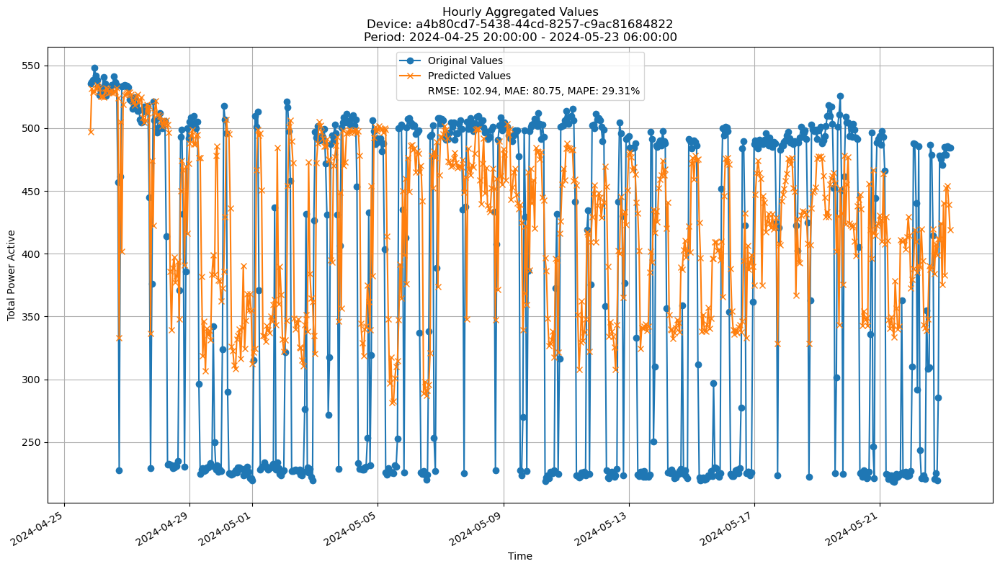

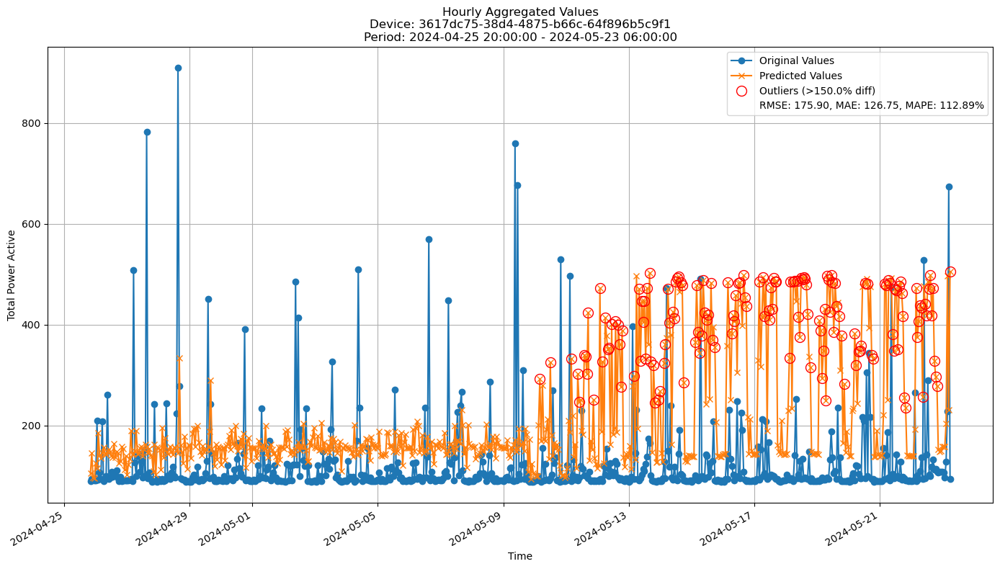

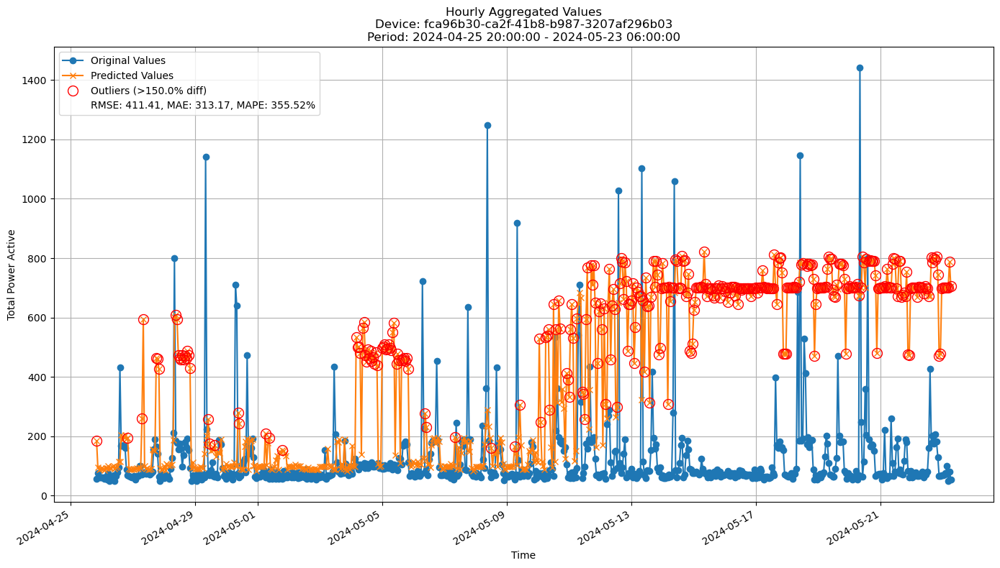

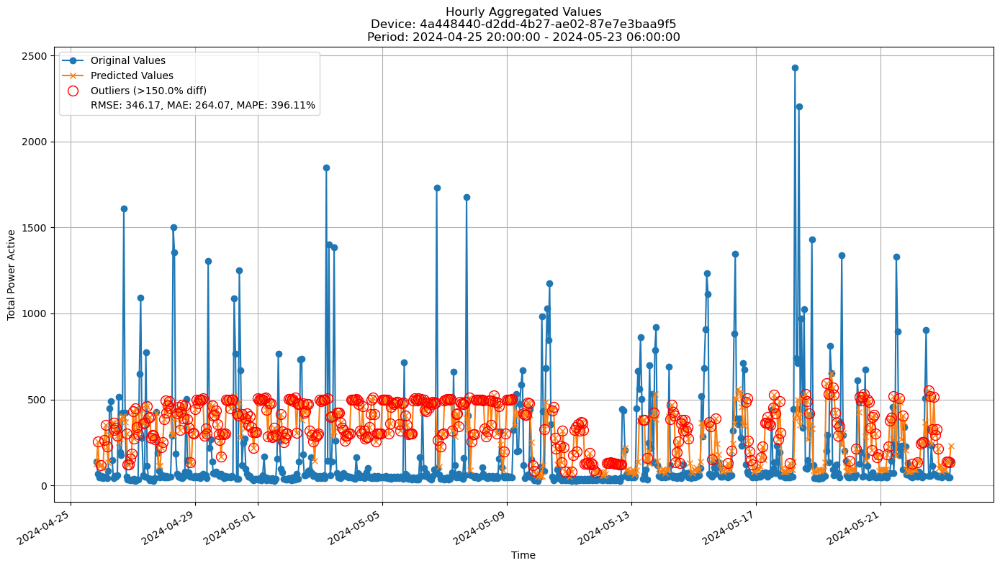

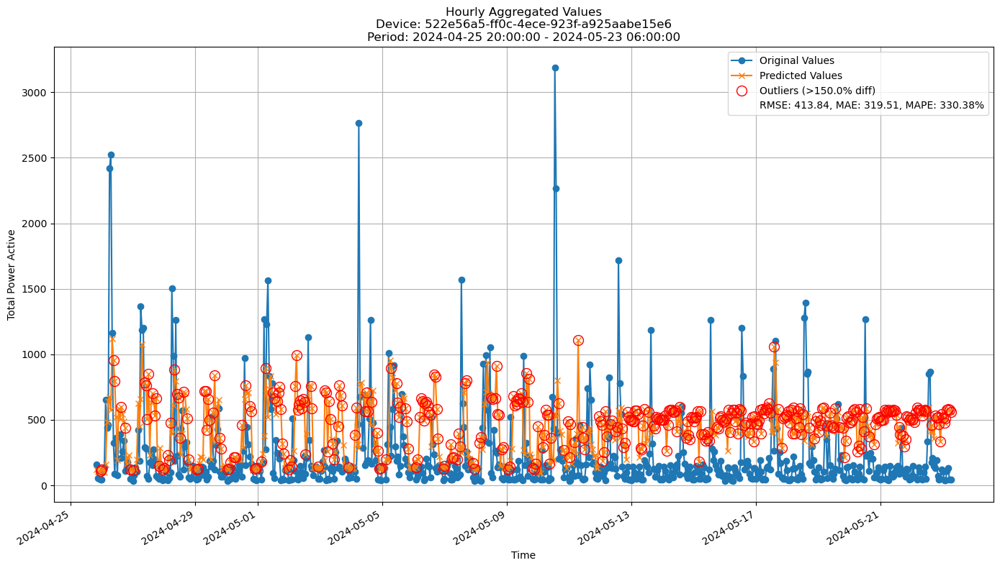

In [29]:
for device_id in rf_valid_period_predictions.keys():
    y_valid = rf_valid_period_predictions[device_id][-1]['y_true']
    y_pred_valid = rf_valid_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### FastODT

In [8]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario
grace_period = 10
split_confidence = 0.55
fodt = fastodt.FastODT(
        depth=20,
        grace_period=grace_period,
        split_confidence=split_confidence,
        option='hf'
    )

fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=fodt, 
    train=train, 
    valid=valid, 
    incremental=True, 
    update_freq=update_freq, 
    start_split=2, 
    end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 2:   0%|          | 0/8 [00:00<?, ?it/s]

Initial training on data from 2024-01-07 23:00:00 to 2024-03-29 08:00:00
Train predictions completed.
Metrics for Device: 4ad3e3e6-5f11-4923-a88d-668b4ddb493a | Period: 2024-03-29 09:00:00 - 2024-04-25 19:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 82.8326
	MAE: 47.0815
	MAPE: 66.8730%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 82.8326
	MAE: 47.0815
	MAPE: 66.8730%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 611.4421
	MAE: 506.4009
	MAPE: 22.0437%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 3020.8205
	MAE: 2805.0059
	MAPE: 23.9553%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 14025.0295
	MAE: 14025.0295
	MAPE: 23.5881%
Initial tra

Processing devices in split 3:   0%|          | 0/8 [00:00<?, ?it/s]

Initial training on data from 2024-01-07 23:00:00 to 2024-04-25 19:00:00
Train predictions completed.
Metrics for Device: 4ad3e3e6-5f11-4923-a88d-668b4ddb493a | Period: 2024-04-25 20:00:00 - 2024-05-23 06:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 94.4915
	MAE: 48.5367
	MAPE: 66.1297%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 94.4915
	MAE: 48.5367
	MAPE: 66.1297%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 702.9375
	MAE: 563.3134
	MAPE: 24.6857%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 3521.2338
	MAE: 3239.7553
	MAPE: 26.2805%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 11336.1498
	MAE: 8099.3883
	MAPE: 26.8523%
Initial trai

In [9]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: 4ad3e3e6-5f11-4923-a88d-668b4ddb493a
--------------------------------------------------
5_min Metrics:
	RMSE: 88.6692 ± 0.8150
	MAE: 45.6722 ± 0.2034
	MAPE: 0.6777 ± 0.0013
Hourly Metrics:
	RMSE: 88.6692 ± 0.8150
	MAE: 45.6722 ± 0.2034
	MAPE: 0.6777 ± 0.0013
Daily Metrics:
	RMSE: 704.0357 ± 9.8872
	MAE: 484.3511 ± 5.7085
	MAPE: 0.2082 ± 0.0015
Weekly Metrics:
	RMSE: 3675.5197 ± 27.2308
	MAE: 2968.0203 ± 71.7649
	MAPE: 0.2817 ± 0.0084
28_days Metrics:
	RMSE: 13882.5455 ± 105.9290
	MAE: 12572.1150 ± 207.5592
	MAPE: 0.2104 ± 0.0029
Device ID: dd40019b-5b35-4fba-b0dd-16083c1fdb84
--------------------------------------------------
5_min Metrics:
	RMSE: 121.1795 ± 6.5525
	MAE: 49.3123 ± 0.6925
	MAPE: 1.0386 ± 0.0878
Hourly Metrics:
	RMSE: 121.1795 ± 6.5525
	MAE: 49.3123 ± 0.6925
	MAPE: 1.0386 ± 0.0878
Daily Metrics:
	RMSE: 810.0034 ± 31.7418
	MAE: 635.9869 ± 49.7459
	MAPE: 0.5954 ± 0.1288
Weekly Metrics:
	RMSE: 3200.0652 

#### Training plots
Plot only the last period of predictions

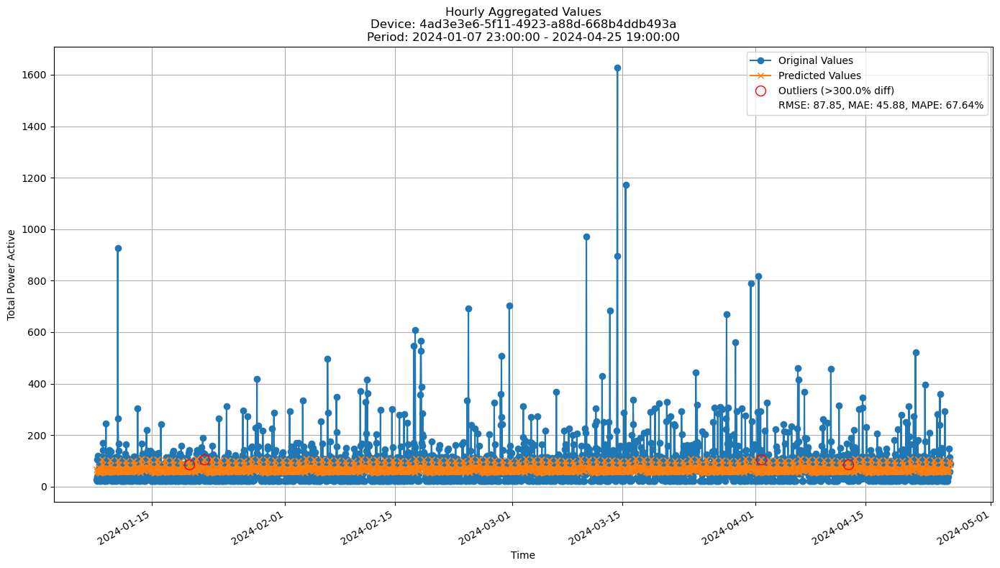

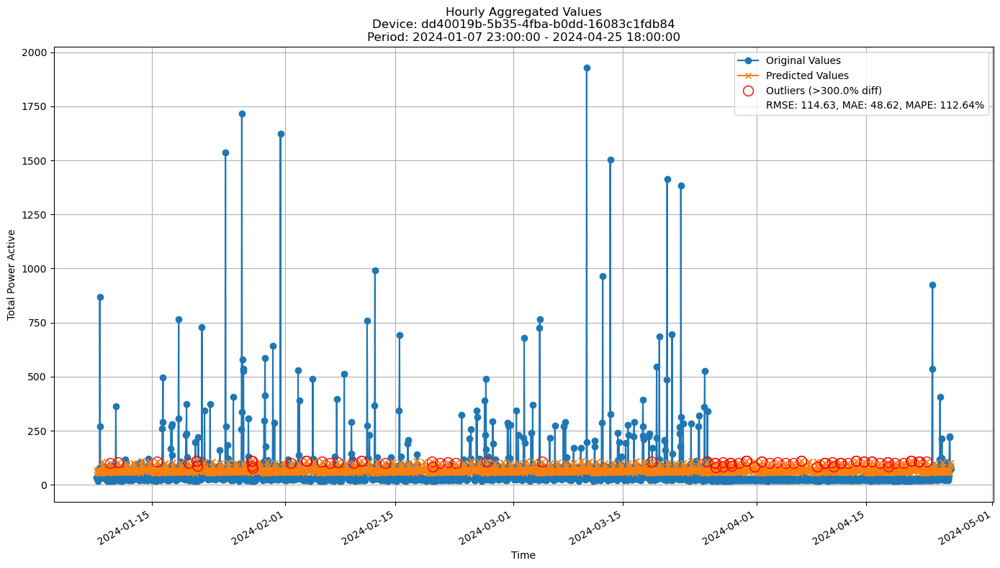

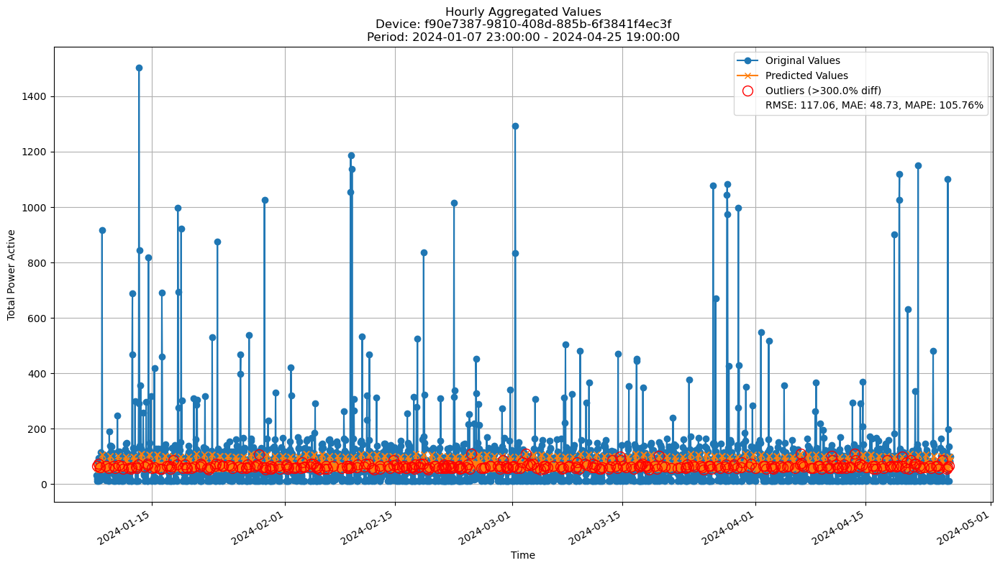

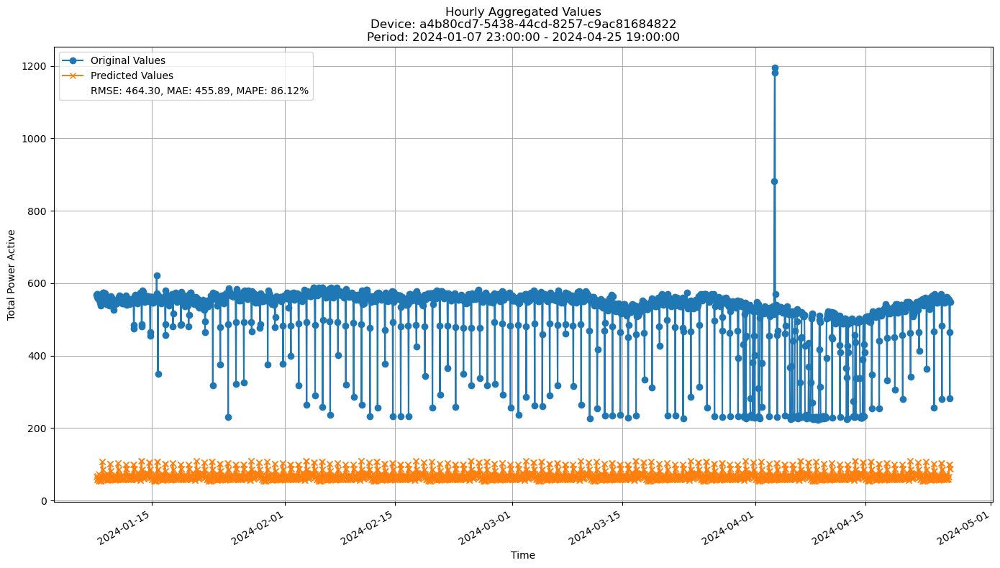

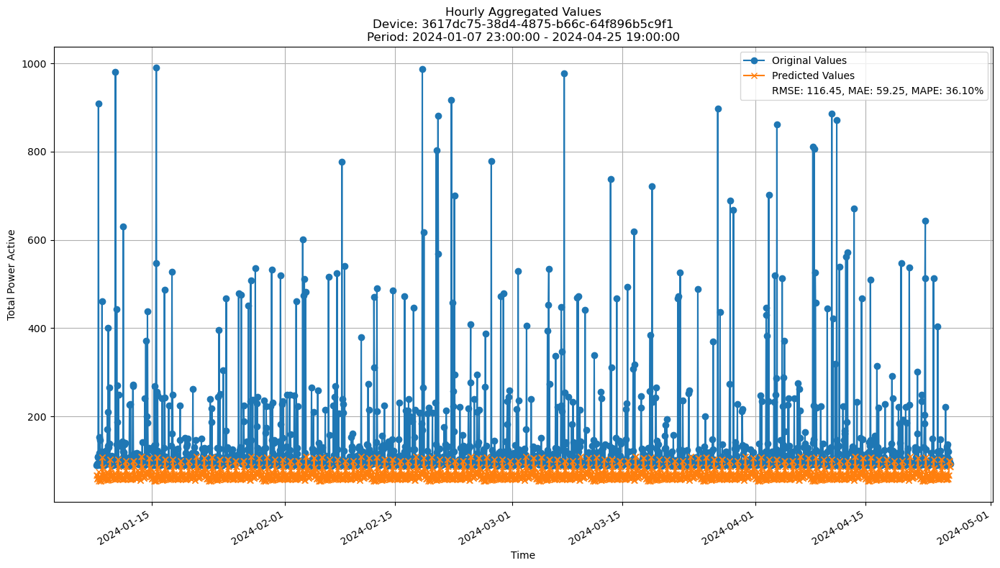

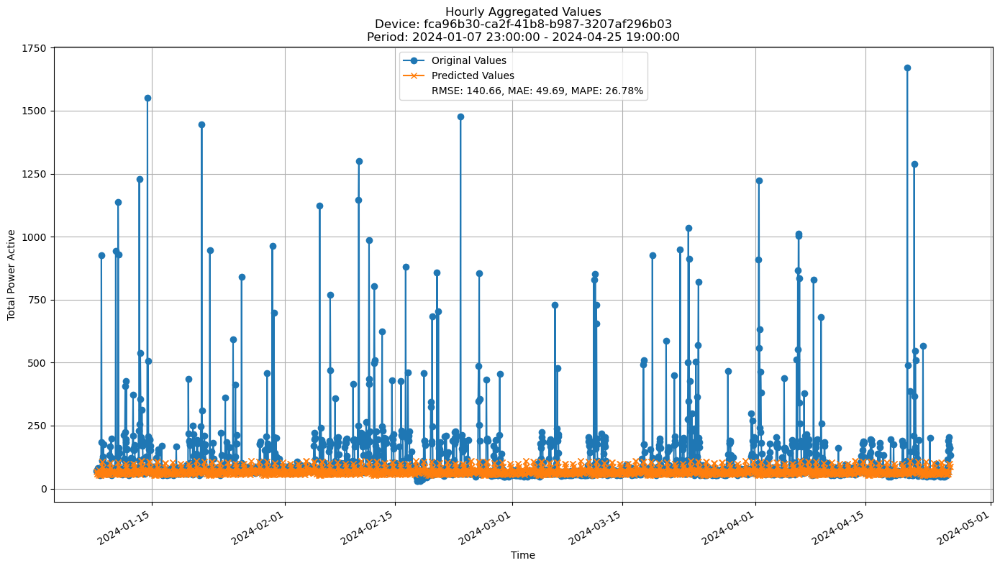

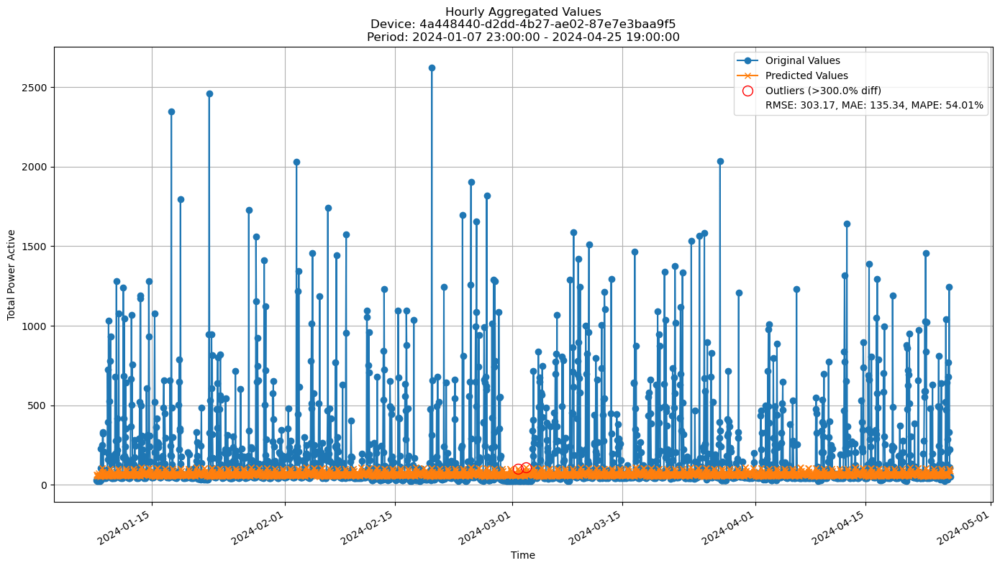

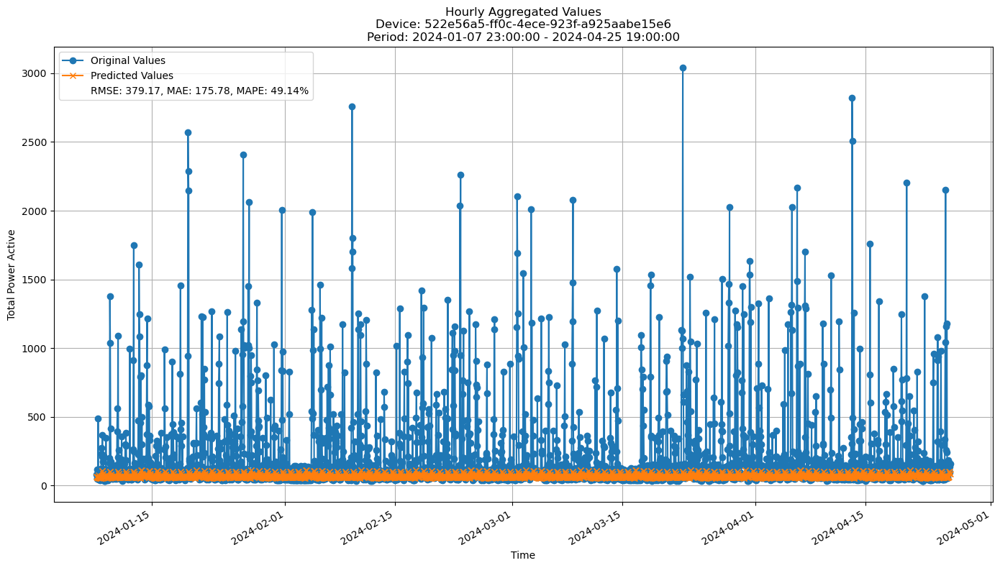

In [10]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=3.0)
# 48, 32, 61

#### Validation plots
Plot only the last period of predictions

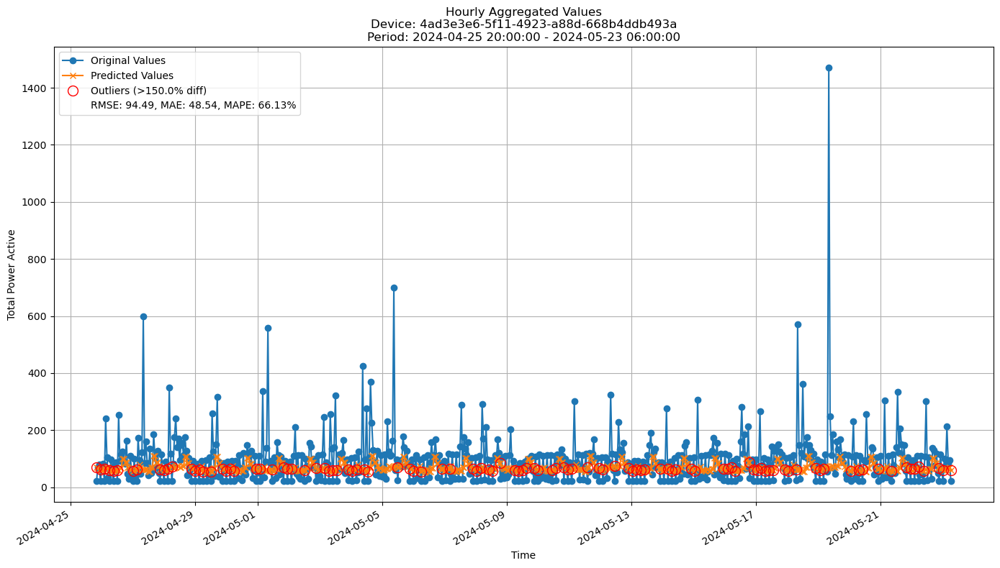

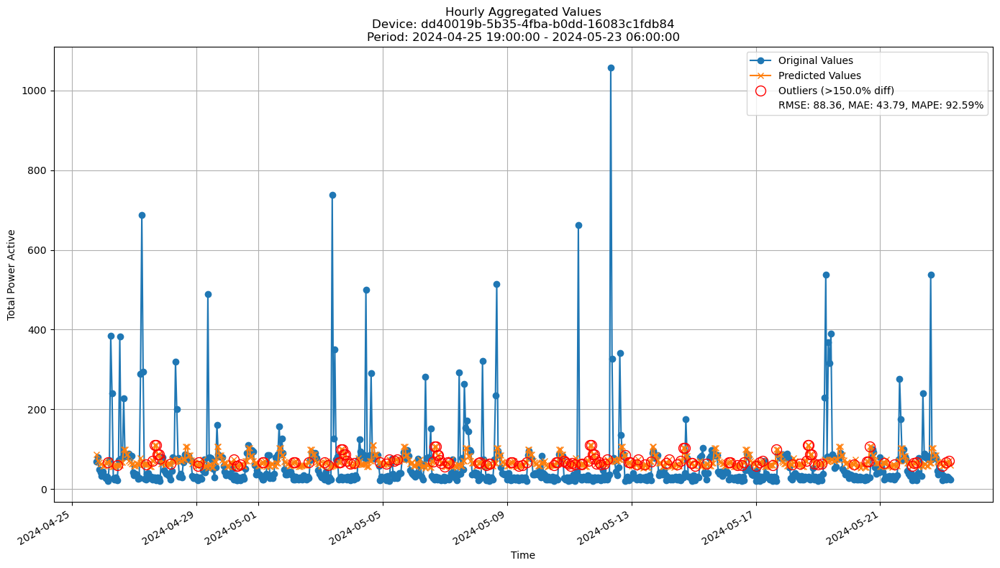

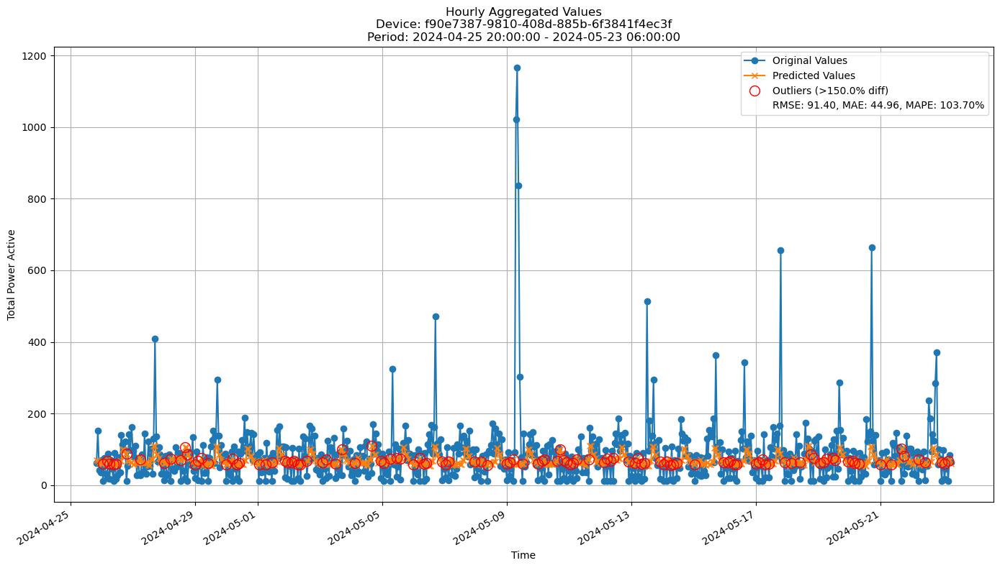

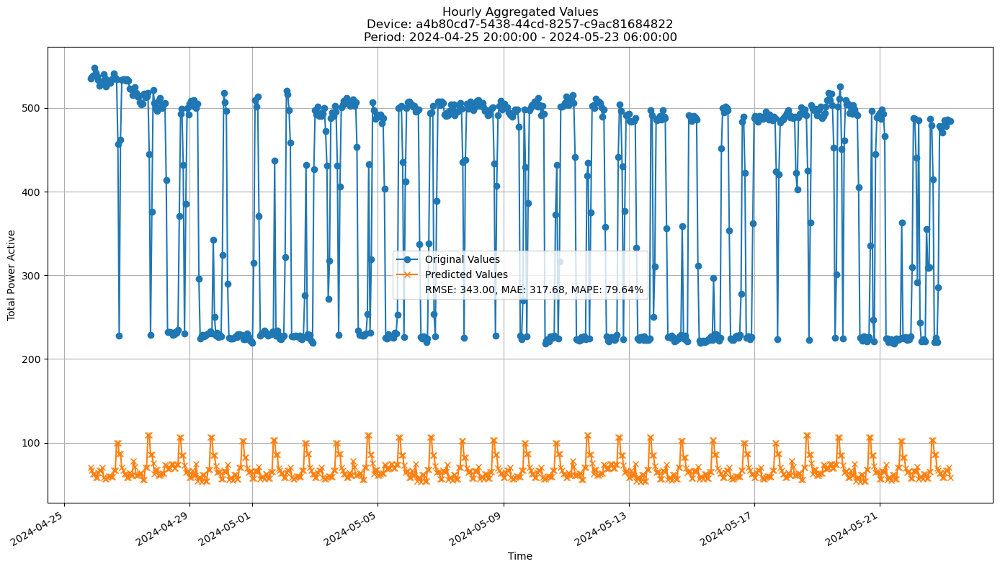

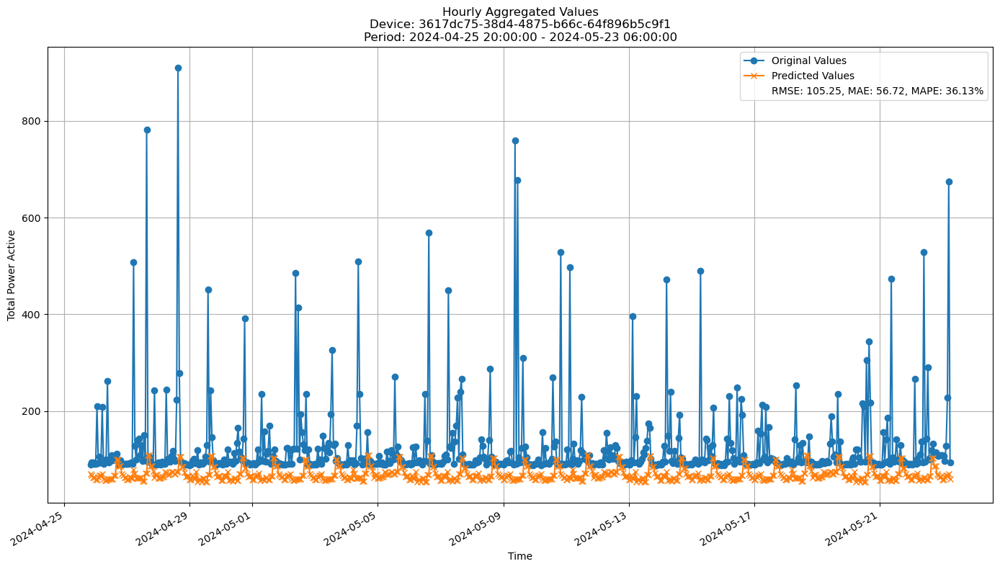

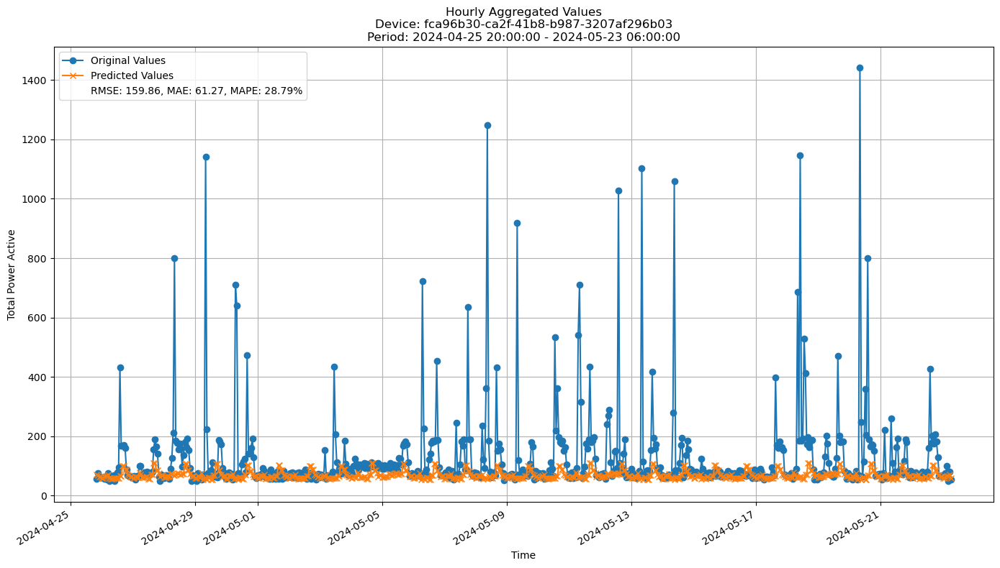

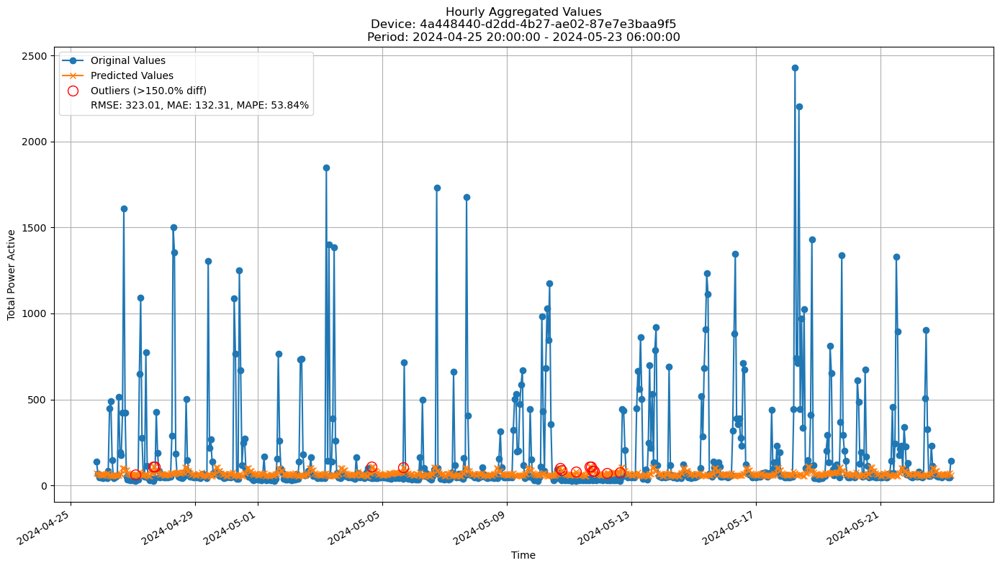

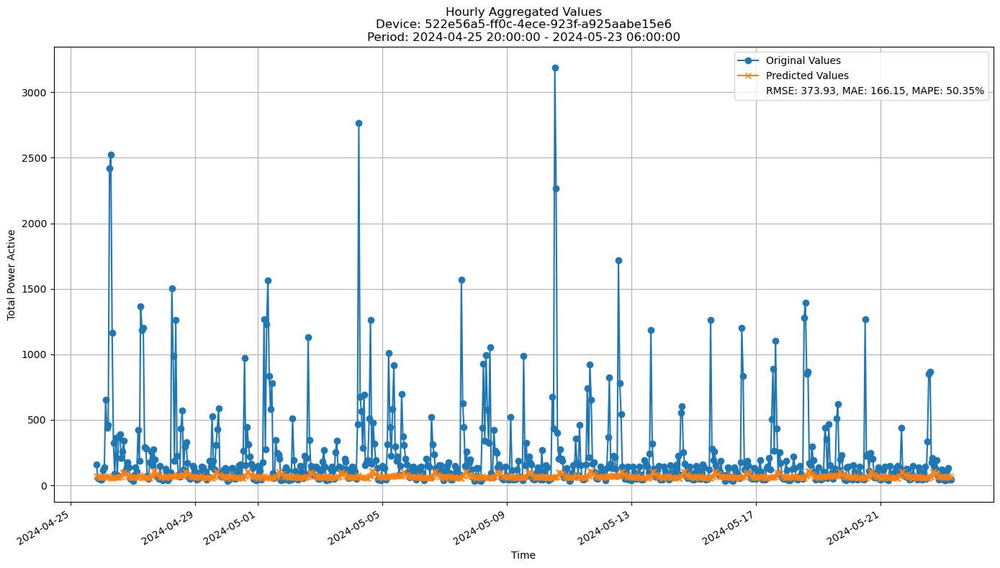

In [27]:
for device_id in fodt_all_valid_preds.keys():
    
    y_valid = fodt_all_valid_preds[device_id][-1]['y_true']
    y_pred_valid = fodt_all_valid_preds[device_id][-1]['y_pred']

    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=1.5)
# 145 115 240

### iNcubation Boost

In [20]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario
split_confidence_hf = 0.05
n_trees = 5
depth = 20
grace_period = 10
incb = IncubationBoost(
    fastodt.FastODT,
    n_trees,
    incubationMode = "SHIFT_LEFT",
    baseLearnerOptions = (depth, grace_period, split_confidence_hf, "hf")
    )

incb_train_period_predictions, incb_valid_period_predictions, \
incb_train_period_metrics, incb_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model=incb, 
    train=train, 
    valid=valid, 
    incremental=True, 
    update_freq=update_freq, 
    start_split=2, 
    end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 2:   0%|          | 0/8 [00:00<?, ?it/s]

Initial training on data from 2024-01-07 23:00:00 to 2024-03-29 08:00:00
Train predictions completed.
Metrics for Device: 4ad3e3e6-5f11-4923-a88d-668b4ddb493a | Period: 2024-03-29 09:00:00 - 2024-04-25 19:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 86.5715
	MAE: 59.3187
	MAPE: 120.2324%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 86.5715
	MAE: 59.3187
	MAPE: 120.2324%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 643.6235
	MAE: 600.3687
	MAPE: 30.6384%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 3320.4114
	MAE: 3095.5605
	MAPE: 26.5212%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 12248.3975
	MAE: 12248.3975
	MAPE: 20.6000%
Initial t

Processing devices in split 3:   0%|          | 0/8 [00:00<?, ?it/s]

Initial training on data from 2024-01-07 23:00:00 to 2024-04-25 19:00:00
Train predictions completed.
Metrics for Device: 4ad3e3e6-5f11-4923-a88d-668b4ddb493a | Period: 2024-04-25 20:00:00 - 2024-05-23 06:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 123.5252
	MAE: 97.2075
	MAPE: 195.3956%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 123.5252
	MAE: 97.2075
	MAPE: 195.3956%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 1979.1658
	MAE: 1720.5377
	MAPE: 89.2640%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 11920.1729
	MAE: 9979.1186
	MAPE: 79.0979%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 25400.0080
	MAE: 18187.9896
	MAPE: 66.8220%
Init

In [21]:
print("\n\nTrain period metrics:")
all_time_train_metrics = all_time_aggregation_metrics(incb_train_period_metrics, verbose=True)
print("\n\Valid period metrics:")
all_time_valid_metrics = all_time_aggregation_metrics(incb_valid_period_metrics, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: 4ad3e3e6-5f11-4923-a88d-668b4ddb493a
--------------------------------------------------
5_min Metrics:
	RMSE: 110.7952 ± 24.7699
	MAE: 82.5909 ± 38.3124
	MAPE: 1.7176 ± 1.0000
Hourly Metrics:
	RMSE: 110.7952 ± 24.7699
	MAE: 82.5909 ± 38.3124
	MAPE: 1.7176 ± 1.0000
Daily Metrics:
	RMSE: 1595.3712 ± 983.9694
	MAE: 1452.9029 ± 1068.2663
	MAPE: 0.7552 ± 0.5869
Weekly Metrics:
	RMSE: 9929.3492 ± 7089.4149
	MAE: 9172.9589 ± 7140.4889
	MAPE: 0.8359 ± 0.6203
28_days Metrics:
	RMSE: 39725.7839 ± 29799.2850
	MAE: 38584.6658 ± 30747.4871
	MAPE: 0.6758 ± 0.5484
Device ID: dd40019b-5b35-4fba-b0dd-16083c1fdb84
--------------------------------------------------
5_min Metrics:
	RMSE: 141.4734 ± 16.9111
	MAE: 92.1018 ± 41.1265
	MAPE: 2.4747 ± 1.4893
Hourly Metrics:
	RMSE: 141.4734 ± 16.9111
	MAE: 92.1018 ± 41.1265
	MAPE: 2.4747 ± 1.4893
Daily Metrics:
	RMSE: 1771.4291 ± 1002.9793
	MAE: 1619.9954 ± 1031.6649
	MAPE: 1.6603 ± 1.1815
We

#### Train plots
Plot only the last period of predictions


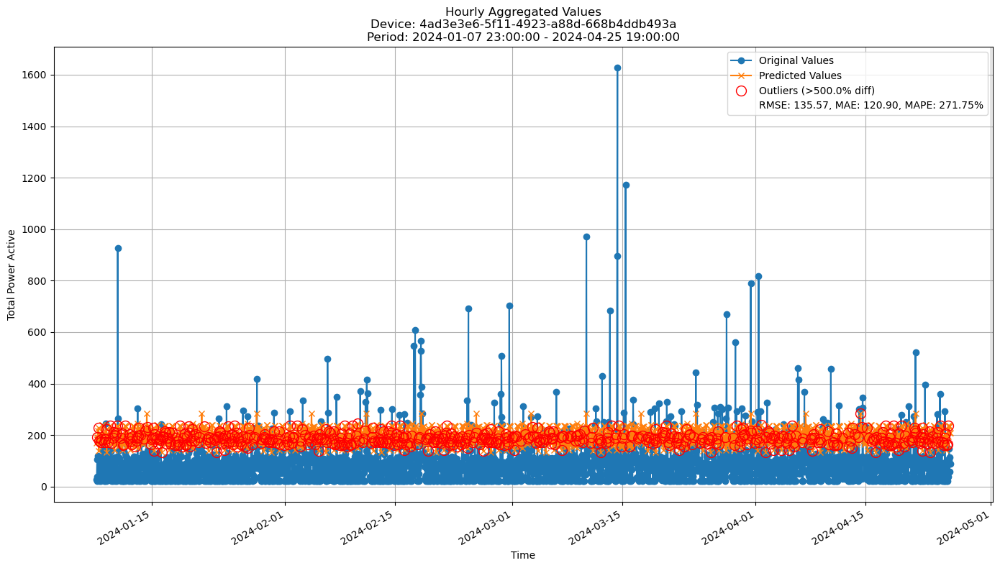

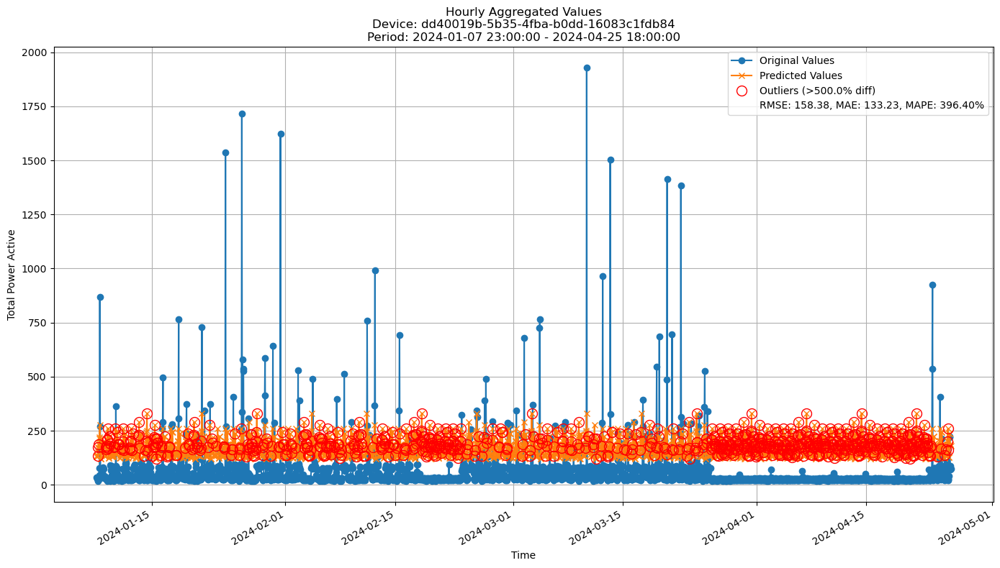

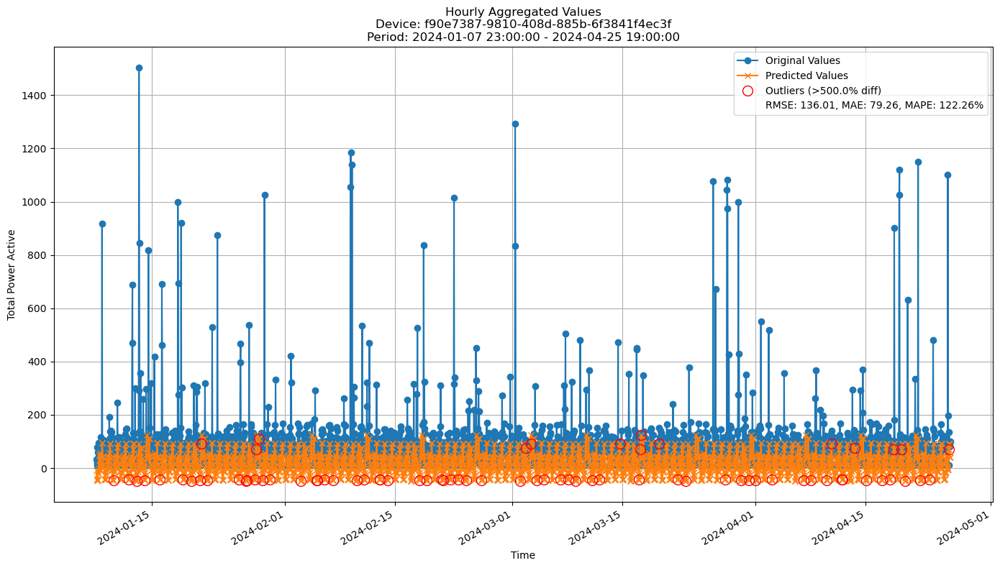

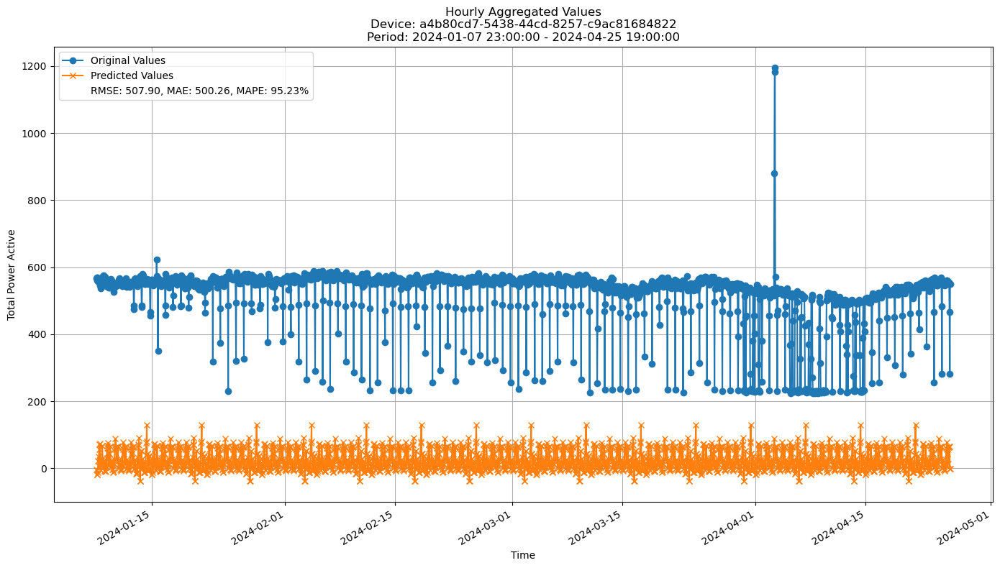

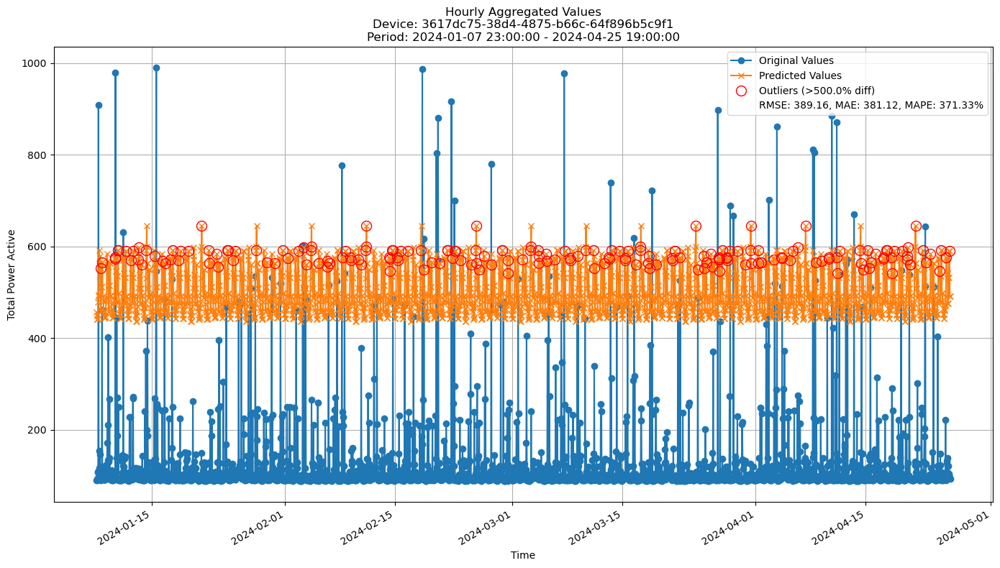

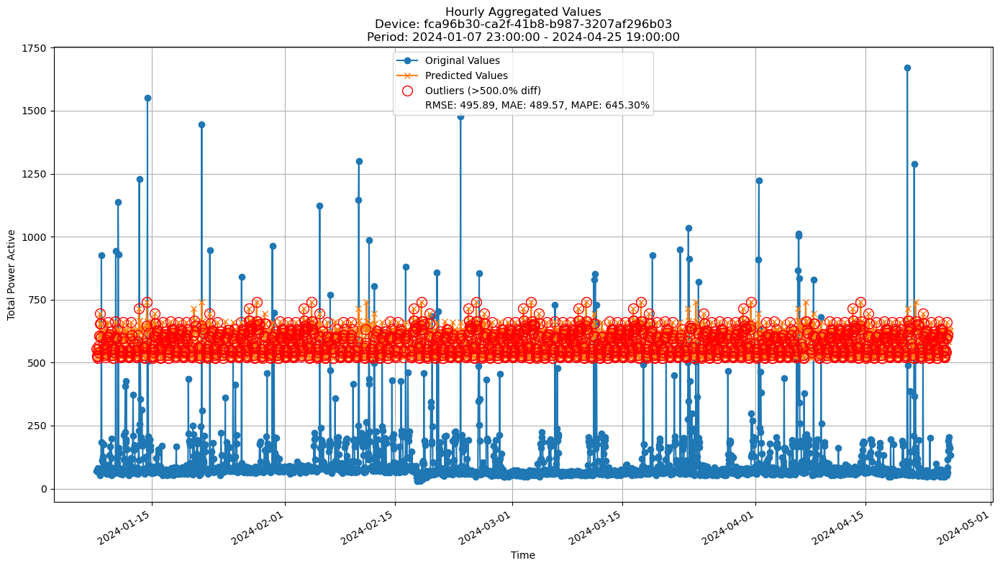

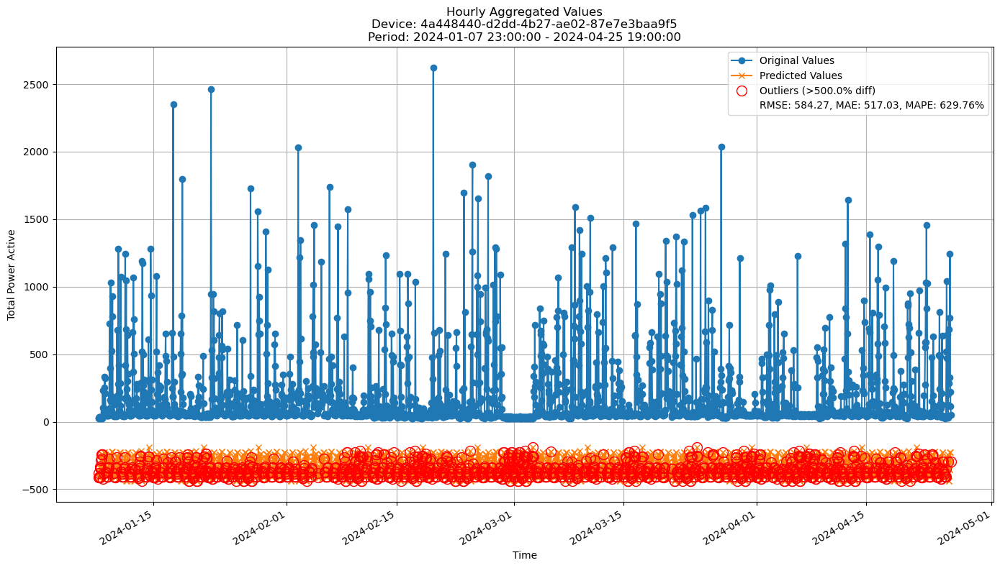

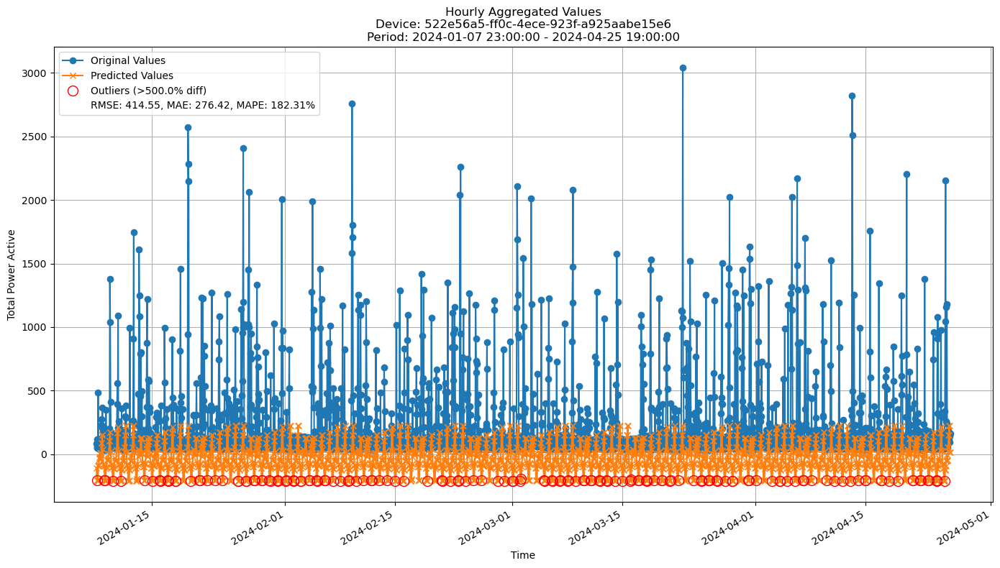

In [24]:
for device_id in incb_train_period_predictions.keys():
    y_train = incb_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = incb_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=5.)

#### Validation plots
Plot only the last period of predictions

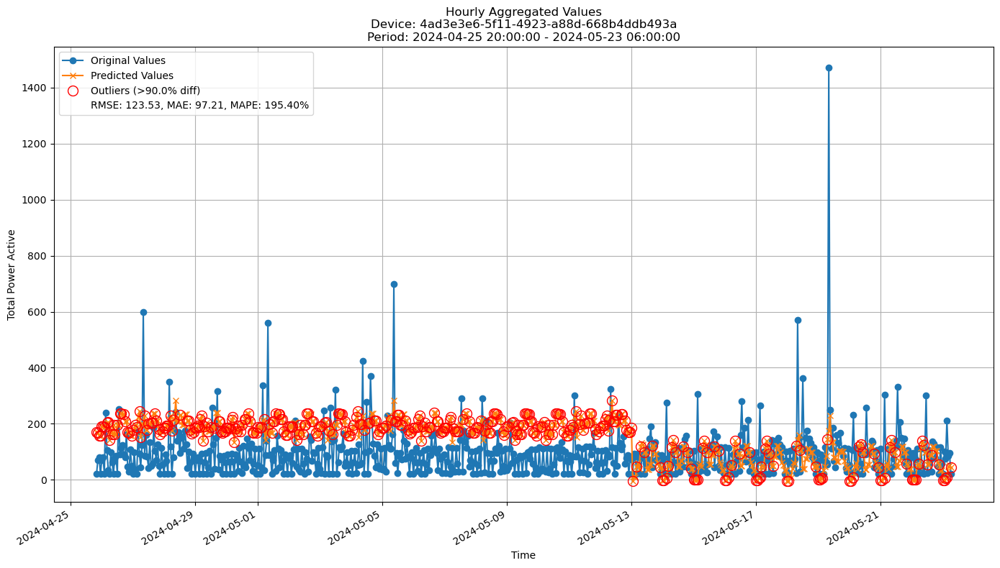

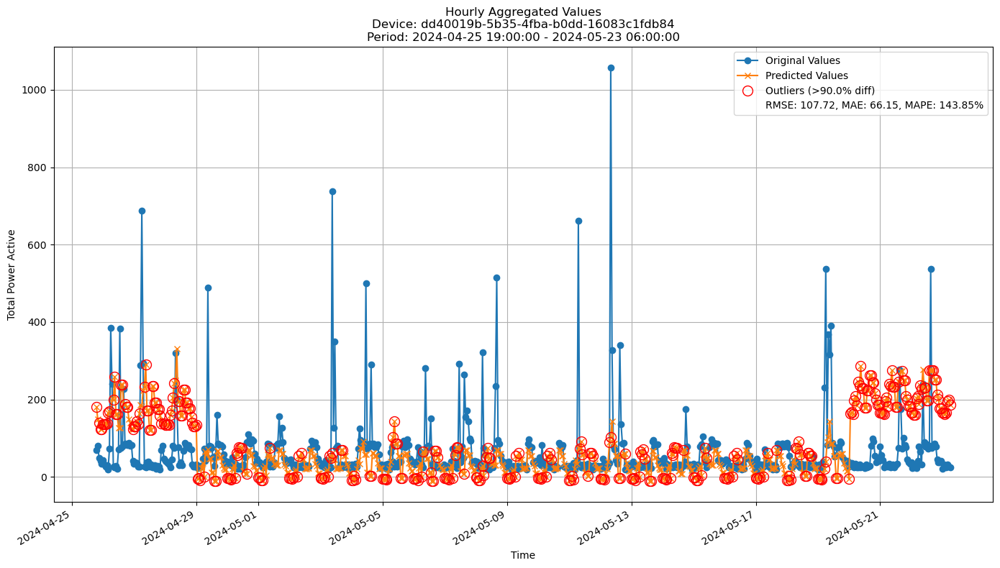

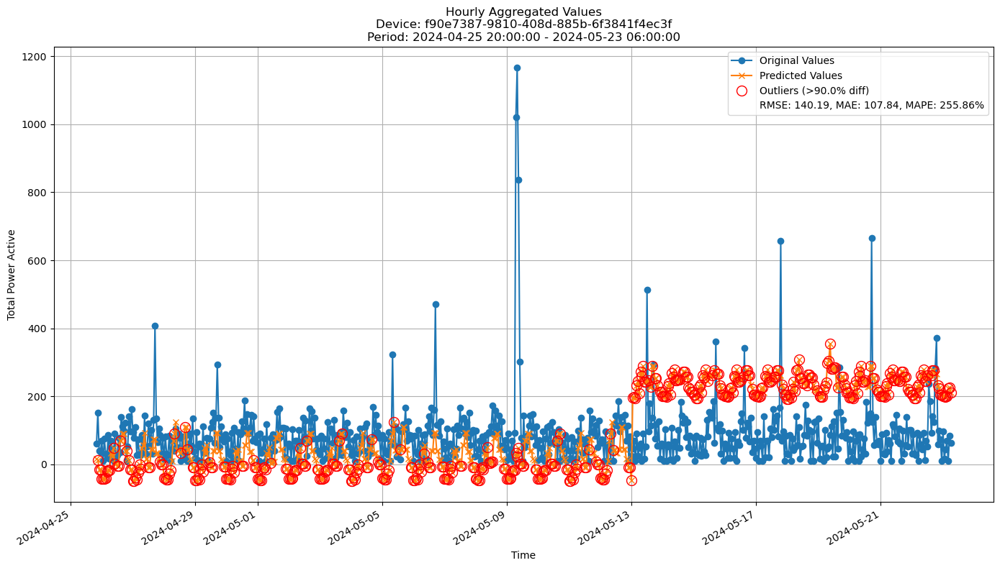

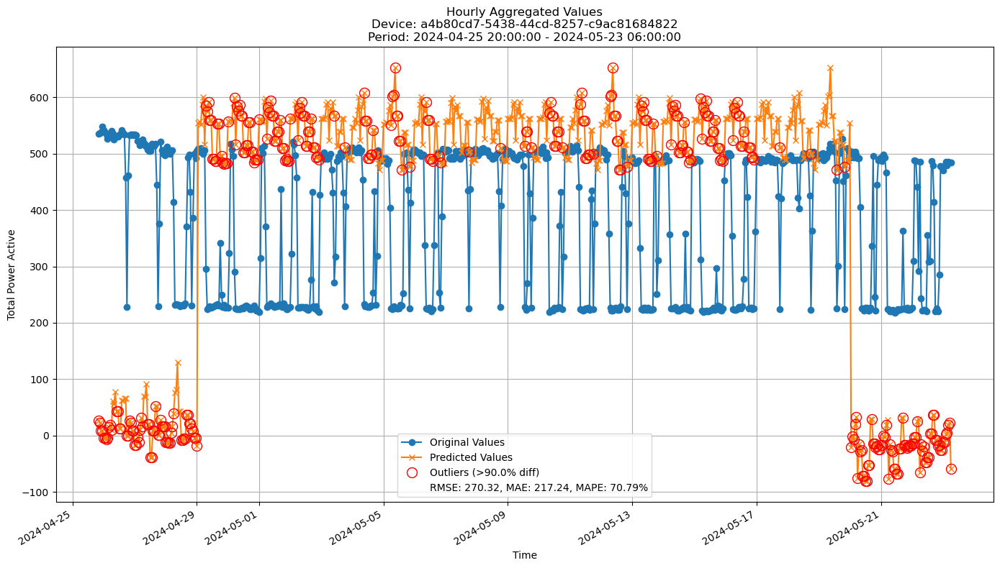

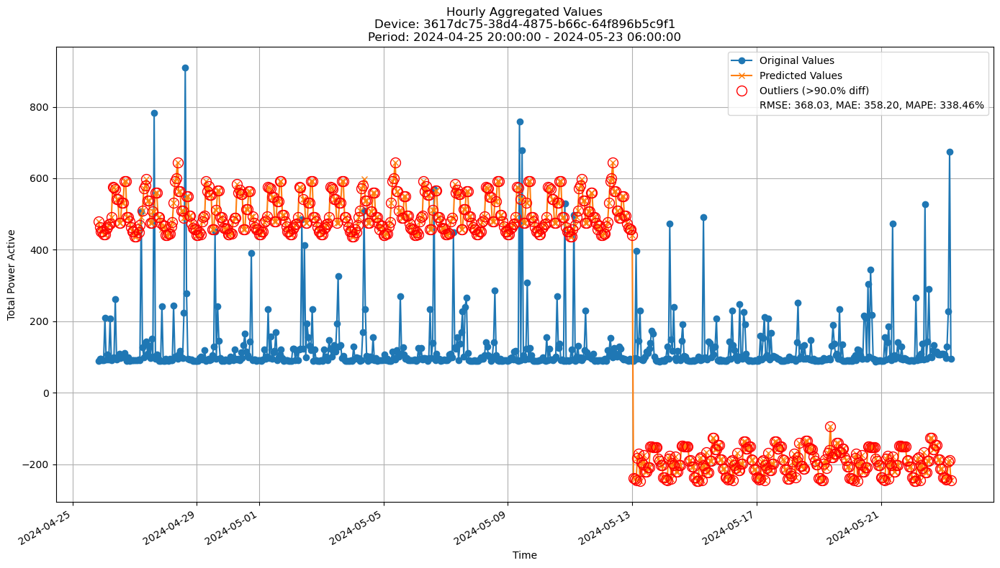

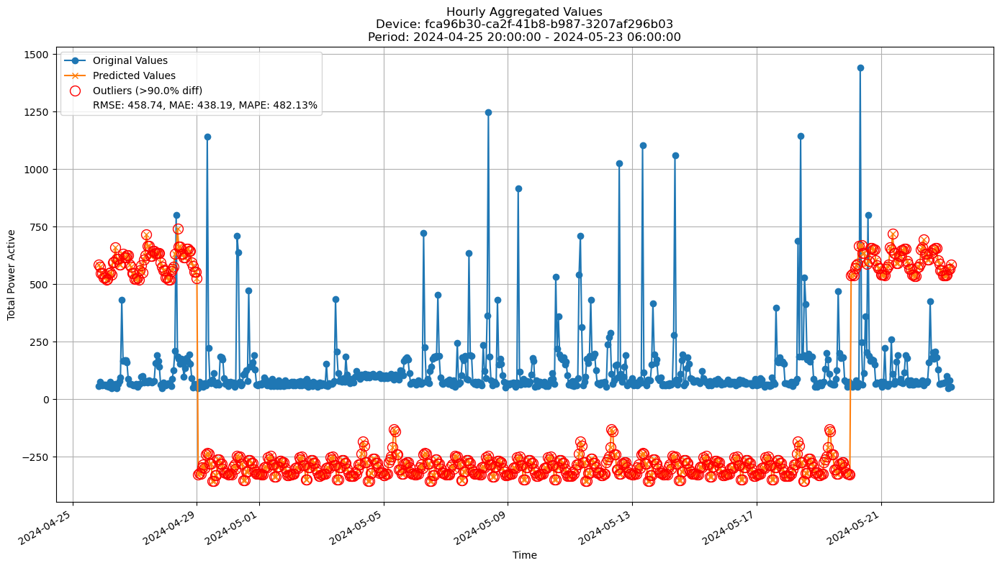

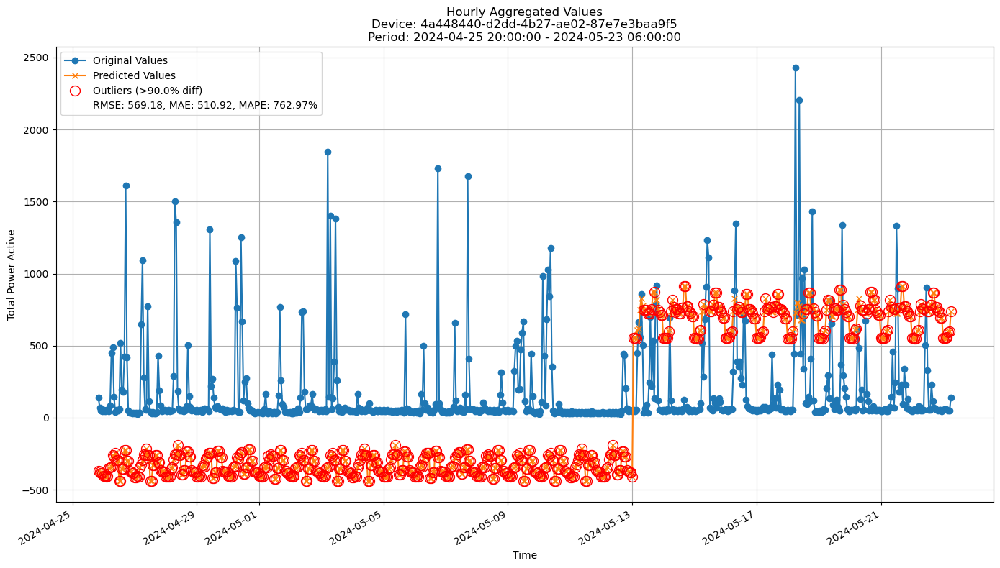

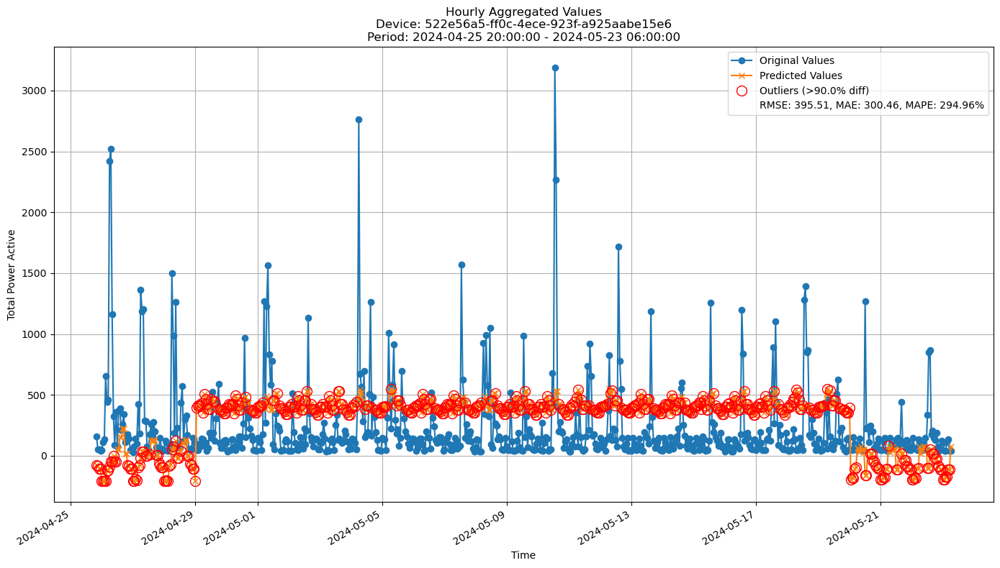

In [23]:
for device_id in incb_valid_period_predictions.keys():
    y_valid = incb_valid_period_predictions[device_id][-1]['y_true']
    y_pred_valid = incb_valid_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=0.9)